# Predicting Sales from Influencer Campaign Data


**Problem statement:**

Marketing teams often invest heavily in influencer campaigns — paying creators to promote products on social media platforms like Instagram. But understanding which factors actually drive product sales is critical to making better decisions about who to work with, how much to spend, and how to design content.

The goal is to build a predictive model that can estimate how many units of a product will be sold based on key influencer campaign attributes.


Complete end-to-end regression notebook for the messy influencer campaign case study.

**Covers:** loading, cleaning, EDA, feature engineering, baseline, model comparison, cross-validation, hyperparameter tuning, evaluation, feature importance, test prediction, reusable prediction pipeline, and exports.

# **Section A: Data Understanding & Cleaning**


## 1. Setup

Download `messy_train_data.csv` and `messy_test_data.csv`. The notebook searches `/content` first and asks for uploads if they are not found.


In [1]:
import os, re, glob, warnings, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Environment ready.")

Environment ready.


In [10]:
# Install gdown
!pip -q install gdown

# Google Drive folder ID
FOLDER_ID = "1BCTayfVYwapGcGl3Mizik1E6-zPcQ_DT"

# Download the entire folder
!gdown --folder "https://drive.google.com/drive/folders/1BCTayfVYwapGcGl3Mizik1E6-zPcQ_DT" -O /content/data

Retrieving folder contents
Processing file 1m3ZO0DctdhpAsF2eyZcKxswkZ5VuurRa messy_test_data.csv
Processing file 17mNOMu0x-8Br9t3J2f0dcLrfq24eWv5Z messy_train_data.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1m3ZO0DctdhpAsF2eyZcKxswkZ5VuurRa
To: /content/data/messy_test_data.csv
100% 162k/162k [00:00<00:00, 2.69MB/s]
Downloading...
From: https://drive.google.com/uc?id=17mNOMu0x-8Br9t3J2f0dcLrfq24eWv5Z
To: /content/data/messy_train_data.csv
100% 709k/709k [00:00<00:00, 2.75MB/s]
Download completed


In [11]:
for root, dirs, files in os.walk("/content/data"):
    for file in files:
        print(os.path.join(root, file))

/content/data/messy_train_data.csv
/content/data/messy_test_data.csv


In [12]:
def load_data(train_path, test_path):

    train_raw = pd.read_csv(train_path)
    test_raw = pd.read_csv(test_path)

    print("Train shape:", train_raw.shape)
    print("Test shape :", test_raw.shape)

    display(train_raw.head())
    display(test_raw.head())

    return train_raw, test_raw

In [13]:
train_path = "/content/data/messy_train_data.csv"
test_path = "/content/data/messy_test_data.csv"

train_raw, test_raw = load_data(train_path, test_path)

Train shape: (8000, 8)
Test shape : (2000, 7)


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),ID,Timestamp,Notes
0,106572.0,2.573174871146172,2614.3781948587675,5.275680,6340,9254,2021-11-27,Pending
1,77583.0,0.9394984315675532,4975.962514379572,8.756268,5793,1561,2022-02-13,Review
2,92832.0,2.1761012652155296,4107.769534318886,6.454727,8104,1670,2023-09-25,Pending
3,53565.0,1.4783757541486553,4293.330464613049,4.312813,7293,6087,2023-02-15,Review
4,121079.0,3.3741976179329356,5343.549440897207,3.769047,14396,6669,2023-05-28,NaN


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,ID,Timestamp,Notes
0,179136.0,2.5570425842061986,3975.099954173261,1.803620,6252,2021-10-08,Good
1,68888.0,3.451254744278324,5392.048613170361,2.993966,4684,2021-10-01,Good
2,89520.0,0.7342357926528821,5850.470394900652,4.525990,1731,2021-06-24,NaN
3,100048.0,1.5972073367018218,5792.432498712002,5.051500,4742,2021-11-22,NaN
4,132229.0,1.3874265375395036,5095.269891920688,3.580921,4521,2021-07-19,Review


## 2. Column Detection and Raw Data Audit

In [14]:
def normalize_column_name(col):
    col = str(col).strip()
    col = re.sub(r"[%()]", "", col)
    col = re.sub(r"[^A-Za-z0-9]+", "_", col)
    col = re.sub(r"_+", "_", col)
    return col.strip("_")

In [15]:
def find_column(df, exact_names=(), contains=None):
    lookup = {c.lower(): c for c in df.columns}
    for name in exact_names:
        if name.lower() in lookup:
            return lookup[name.lower()]
    if contains:
        for c in df.columns:
            if contains.lower() in c.lower():
                return c
    return None

In [16]:
def prepare_data(train_raw, test_raw):
    # Create copies to preserve the original datasets
    train = train_raw.copy()
    test = test_raw.copy()

    # Normalize column names
    train.columns = [normalize_column_name(c) for c in train.columns]
    test.columns = [normalize_column_name(c) for c in test.columns]

    # Detect required columns
    TARGET = find_column(train, ["Sales", "sales_units", "units_sold"], "sales")
    FOLLOWERS_COL = find_column(train, ["Followers", "followers_count"], "follower")
    ENGAGEMENT_COL = find_column(train, ["EngagementRate", "Engagement_Rate"], "engagement")
    ADSPEND_COL = find_column(train, ["AdSpend", "Ad_Spend"], "spend")
    CONTENT_COL = find_column(train, ["ContentQuality", "Content_Quality"], "content")
    TIMESTAMP_COL = find_column(train, ["Timestamp", "CampaignTimestamp", "Date"], "timestamp")

    # Display detected columns
    print("TARGET          :", TARGET)
    print("FOLLOWERS       :", FOLLOWERS_COL)
    print("ENGAGEMENT RATE :", ENGAGEMENT_COL)
    print("AD SPEND        :", ADSPEND_COL)
    print("CONTENT QUALITY :", CONTENT_COL)
    print("TIMESTAMP       :", TIMESTAMP_COL)

    # Validate target column
    if TARGET is None:
        raise ValueError("Sales target column could not be detected.")

    # Return datasets and detected column names
    columns = {
        "TARGET": TARGET,
        "FOLLOWERS_COL": FOLLOWERS_COL,
        "ENGAGEMENT_COL": ENGAGEMENT_COL,
        "ADSPEND_COL": ADSPEND_COL,
        "CONTENT_COL": CONTENT_COL,
        "TIMESTAMP_COL": TIMESTAMP_COL
    }

    return train, test, columns

In [17]:
# Call the function
train, test, columns = prepare_data(train_raw, test_raw)

# Access detected column names
TARGET = columns["TARGET"]
FOLLOWERS_COL = columns["FOLLOWERS_COL"]
ENGAGEMENT_COL = columns["ENGAGEMENT_COL"]
ADSPEND_COL = columns["ADSPEND_COL"]
CONTENT_COL = columns["CONTENT_COL"]
TIMESTAMP_COL = columns["TIMESTAMP_COL"]


TARGET          : Sales_Units
FOLLOWERS       : Followers
ENGAGEMENT RATE : EngagementRate
AD SPEND        : AdSpend_GBP
CONTENT QUALITY : ContentQuality
TIMESTAMP       : Timestamp


**Data Quality Assessment (EDA)**

In [20]:
def analyze_data_quality(train):
    # Generate data quality report
    quality = pd.DataFrame({
        "dtype": train.dtypes.astype(str),
        "missing": train.isna().sum(),
        "missing_pct": train.isna().mean().mul(100).round(2),
        "unique": train.nunique()
    }).sort_values("missing_pct", ascending=False)

    print("DATA QUALITY REPORT")
    display(quality)

    # Display sample values for each column
    for col in train.columns:
        print("\n" + "=" * 60)
        print(f"Column: {col}")
        print(train[col].dropna().astype(str).head(10).tolist())

    return quality


In [139]:
# Call the function
quality = analyze_data_quality(train)


DATA QUALITY REPORT


,dtype,missing,missing_pct,unique
Notes,object,2652,33.15,4
EngagementRate,float64,163,2.04,7797
AdSpend_GBP,float64,162,2.02,7811
Followers,float64,160,2.00,7403
ContentQuality,float64,160,2.00,7840
Sales_Units,float64,0,0.00,5582
ID,int64,0,0.00,8000
Timestamp,object,0,0.00,1000



Column: Followers
['106572.0', '77583.0', '92832.0', '53565.0', '121079.0', '30578.0', '62648.0', '71757.0', '115007.0', '76227.0']

Column: EngagementRate
['0.025731748711461718', '0.009394984315675531', '0.021761012652155295', '0.014783757541486553', '0.03374197617932936', '0.029606091166153047', '0.04661459088961558', '0.03342101492655889', '0.03089165291715726', '0.027434519524908194']

Column: AdSpend_GBP
['2614.3781948587675', '4975.962514379572', '4107.769534318886', '4293.330464613049', '5343.549440897207', '6640.860427448698', '3594.5211897372737', '4447.20233454365', '3940.505439955562', '7594.681081184365']

Column: ContentQuality
['5.2756801191454885', '8.75626791367936', '6.454726997519417', '4.31281296087897', '3.769046633115465', '8.643337185416053', '2.951550238875863', '1.6655886303503693', '3.131948518566964', '3.1517547687668253']

Column: Sales_Units
['6340.0', '5793.0', '8104.0', '7293.0', '14396.0', '8478.0', '7493.0', '6932.0', '9209.0', '11357.0']

Column: ID
[

## 3. Data Cleaning

The parser handles values such as `£5000`, `5,000`, `3.2%`, `250K`, `1.5M`, `2B`, and parenthesized negatives.

Impossible business values are converted to missing so that the model's imputation pipeline can handle them without leaking validation/test information.


In [22]:
def parse_numeric(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float, np.integer, np.floating)):
        return float(value)

    s = str(value).strip()
    if not s:
        return np.nan

    negative = s.startswith("(") and s.endswith(")")
    s = s.replace(",", "")
    is_percent = "%" in s

    suffix_match = re.search(r"([KkMmBb])$", s)
    multiplier = 1.0

    if suffix_match:
        multiplier = {
            "K": 1e3,
            "M": 1e6,
            "B": 1e9
        }[suffix_match.group(1).upper()]
        s = s[:-1]

    s = re.sub(r"[^0-9eE.+-]", "", s)

    if not s:
        return np.nan

    try:
        x = float(s) * multiplier
        if negative:
            x = -x
        if is_percent:
            x /= 100.0
        return x
    except Exception:
        return np.nan

In [23]:
def clean_core(df, include_target=False):
    df = df.copy()

    numeric_cols = [
        FOLLOWERS_COL,
        ENGAGEMENT_COL,
        ADSPEND_COL,
        CONTENT_COL
    ]

    if include_target:
        numeric_cols.append(TARGET)

    for col in numeric_cols:
        if col and col in df.columns:
            df[col] = df[col].apply(parse_numeric)

    # Standardize percentage-point engagement rates.
    if ENGAGEMENT_COL and ENGAGEMENT_COL in df.columns:
        med = df[ENGAGEMENT_COL].median()
        if pd.notna(med) and med > 1:
            df[ENGAGEMENT_COL] = df[ENGAGEMENT_COL] / 100.0

    # Business validation.
    if FOLLOWERS_COL in df.columns:
        df.loc[df[FOLLOWERS_COL] < 0, FOLLOWERS_COL] = np.nan

    if ADSPEND_COL in df.columns:
        df.loc[df[ADSPEND_COL] < 0, ADSPEND_COL] = np.nan

    if ENGAGEMENT_COL in df.columns:
        df.loc[
            (df[ENGAGEMENT_COL] < 0) | (df[ENGAGEMENT_COL] > 1),
            ENGAGEMENT_COL
        ] = np.nan

    if CONTENT_COL in df.columns:
        df.loc[
            (df[CONTENT_COL] < 1) | (df[CONTENT_COL] > 10),
            CONTENT_COL
        ] = np.nan

    if include_target and TARGET in df.columns:
        df.loc[df[TARGET] < 0, TARGET] = np.nan

    return df

In [24]:

train = clean_core(train, include_target=True)
test = clean_core(test, include_target=False)

print("Cleaning completed.")


Cleaning completed.


# **Section B: Exploratory Data Analysis (EDA)**

In [138]:
def inspect_extreme_values(
    train,
    followers_col,
    adspend_col,
    target_col,
    top_n=10
):
    required_cols = [followers_col, adspend_col, target_col]

    missing_cols = [c for c in required_cols if c not in train.columns]
    if missing_cols:
        raise ValueError(f"Missing columns: {missing_cols}")

    print("=" * 60)
    print("EXTREME VALUE AND DATA QUALITY REPORT")
    print("=" * 60)

    # 1. Follower distribution
    print("\n1. FOLLOWER COUNT DISTRIBUTION")
    display(
        train[followers_col]
        .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
        .to_frame()
    )

    print(f"\n2. TOP {top_n} FOLLOWER COUNTS")
    display(
        train.nlargest(top_n, followers_col)[
            [followers_col, target_col]
        ]
    )

    # 2. Advertising spend distribution
    print("\n3. AD SPEND DISTRIBUTION")
    display(
        train[adspend_col]
        .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
        .to_frame()
    )

    print(f"\n4. TOP {top_n} AD SPEND VALUES")
    display(
        train.nlargest(top_n, adspend_col)[
            [adspend_col, target_col]
        ]
    )

    # 3. Negative values
    print("\n5. NEGATIVE VALUES")
    print("Negative followers:", (train[followers_col] < 0).sum())
    print("Negative ad spend:", (train[adspend_col] < 0).sum())
    print("Negative sales:", (train[target_col] < 0).sum())

    # 4. Missing values
    print("\n6. MISSING VALUES")
    display(train[required_cols].isna().sum().to_frame("Missing_Count"))

    # 5. Flag extreme values using the IQR rule
    print("\n7. POTENTIAL EXTREME VALUES (IQR RULE)")

    for col in [followers_col, adspend_col]:
        values = train[col].dropna()

        if values.empty:
            print(f"{col}: No valid numeric values.")
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        extreme_mask = (train[col] < lower) | (train[col] > upper)

        print(f"\n{col}")
        print(f"Lower IQR boundary: {lower:,.2f}")
        print(f"Upper IQR boundary: {upper:,.2f}")
        print(f"Potential extreme rows: {extreme_mask.sum()}")

        display(
            train.loc[extreme_mask, [col, target_col]]
            .sort_values(col, ascending=False)
            .head(top_n)
        )

    print("\nInspection completed. No data was modified.")


# Run the function
inspect_extreme_values(
    train=train,
    followers_col=FOLLOWERS_COL,
    adspend_col=ADSPEND_COL,
    target_col=TARGET,
    top_n=10
)

EXTREME VALUE AND DATA QUALITY REPORT

1. FOLLOWER COUNT DISTRIBUTION


,Followers
count,7.840000e+03
mean,1.111104e+06
std,4.013038e+07
min,2.000000e+01
50%,9.912050e+04
90%,1.381325e+05
95%,1.491790e+05
99%,1.699803e+05
max,1.629447e+09



2. TOP 10 FOLLOWER COUNTS


,Followers,Sales_Units
6769,1.629447e+09,12303.0
5961,1.620720e+09,13875.0
3838,1.598940e+09,9705.0
605,1.551667e+09,10828.0
3245,1.545246e+09,14840.0
348,2.000000e+05,19286.0
4142,2.000000e+05,15494.0
4778,2.000000e+05,16934.0
7193,2.000000e+05,15660.0
5964,1.972920e+05,17855.0



3. AD SPEND DISTRIBUTION


...


7. POTENTIAL EXTREME VALUES (IQR RULE)

Followers
Lower IQR boundary: 15,208.00
Upper IQR boundary: 182,660.00
Potential extreme rows: 231


,Followers,Sales_Units
6769,1.629447e+09,12303.0
5961,1.620720e+09,13875.0
3838,1.598940e+09,9705.0
605,1.551667e+09,10828.0
3245,1.545246e+09,14840.0
4778,2.000000e+05,16934.0
348,2.000000e+05,19286.0
4142,2.000000e+05,15494.0
7193,2.000000e+05,15660.0
5964,1.972920e+05,17855.0



AdSpend_GBP
Lower IQR boundary: 933.27
Upper IQR boundary: 9,048.09
Potential extreme rows: 25


,AdSpend_GBP,Sales_Units
3953,9.322339e+08,11608.0
5174,4.414560e+08,9557.0
7993,1.016000e+08,11883.0
4462,1.000000e+04,18958.0
5914,1.000000e+04,14611.0
4134,9.823061e+03,16599.0
6319,9.738413e+03,15408.0
7752,9.705029e+03,19789.0
7950,9.698489e+03,16024.0
4417,9.557422e+03,16450.0



Inspection completed. No data was modified.


In [43]:
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Followers,7840.0,NaN,NaN,NaN,1111104.467602,40130384.889415,20.0,78002.5,99120.5,119865.5,1629447388.0
EngagementRate,7837.0,NaN,NaN,NaN,0.027118,0.013588,0.000051,0.015589,0.027492,0.038823,0.049997
AdSpend_GBP,7838.0,NaN,NaN,NaN,193216.820368,11706360.763946,1000.0,3976.328415,5006.486783,6005.033554,932233948.827557
ContentQuality,7840.0,NaN,NaN,NaN,5.492899,2.608038,1.000151,3.227357,5.468786,7.780281,9.999749
Sales_Units,8000.0,NaN,NaN,NaN,10544.674375,2808.151485,590.0,8642.25,10500.0,12459.0,20263.0
ID,8000.0,NaN,NaN,NaN,5011.506875,2887.649416,1.0,2511.75,5013.5,7504.25,9999.0
Timestamp,8000,1000,2022-09-17,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Notes,5348,4,Pending,1367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. plot_sales_distribution(train, TARGET) — understand the sales distribution.

In [27]:
def plot_sales_distribution(train, target_col):
    # 1. Sales Distribution
    plt.figure(figsize=(10, 5))
    plt.hist(train[target_col].dropna(), bins=40)
    plt.xlabel("Sales (Units)")
    plt.ylabel("Campaign Count")
    plt.title("Sales Distribution")
    plt.show()

    # 2. Filter non-negative sales values
    positive_sales = train.loc[
        train[target_col].notna() & (train[target_col] >= 0),
        target_col
    ]

    # 3. Log Sales Distribution
    plt.figure(figsize=(10, 5))
    plt.hist(np.log1p(positive_sales), bins=40)
    plt.xlabel("log(1 + Sales)")
    plt.ylabel("Campaign Count")
    plt.title("Log Sales Distribution")
    plt.show()

    return positive_sales

## 2. analyze_correlations(train, TARGET, feature_cols) — examine feature relationships.

In [30]:
def analyze_correlations(
    train,
    target_col,
    feature_cols
):
    # 1. Correlation Matrix
    numeric_data = train.select_dtypes(include=np.number)
    corr = numeric_data.corr(numeric_only=True)

    plt.figure(figsize=(12, 8))
    plt.imshow(corr, aspect="auto")
    plt.colorbar()

    plt.xticks(
        range(len(corr.columns)),
        corr.columns,
        rotation=90
    )
    plt.yticks(range(len(corr.columns)),corr.columns)

    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    # 2. Sales vs. Individual Features
    for col in feature_cols:
        if col and col in train.columns:
            tmp = train[[col, target_col]].dropna()

            if tmp.empty:
                print(f"Skipping {col}: no valid data.")
                continue

            plt.figure(figsize=(8, 5))
            plt.scatter(tmp[col],tmp[target_col],alpha=0.5)
            plt.xlabel(col)
            plt.ylabel("Sales")
            plt.title(f"Sales vs {col}")
            plt.tight_layout()
            plt.show()
    return corr

## 3. compare_campaign_performance(train, TARGET, feature_cols) — compare successful and unsuccessful campaigns.

In [44]:
def compare_campaign_performance(train, target_col, feature_cols):
    df = train.copy()
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
    df = df.dropna(subset=[target_col])

    if df.empty:
        print("No valid sales data available.")
        return None

    # Divide campaigns into performance groups
    low_threshold = df[target_col].quantile(0.25)
    high_threshold = df[target_col].quantile(0.75)

    df["Performance"] = np.select(
        [
            df[target_col] <= low_threshold,
            df[target_col] >= high_threshold
        ],
        ["Low Performing", "High Performing"],
        default="Average Performing"
    )

    valid_features = [
        col for col in feature_cols
        if col and col in df.columns
        and col != target_col
    ]

    if not valid_features:
        print("No valid feature columns found.")
        return None

    comparison = df.groupby("Performance", observed=False)[
        valid_features
    ].mean().T

    print("Average Feature Values by Campaign Performance")
    display(comparison)

    comparison.plot(kind="bar", figsize=(12, 6))
    plt.title("High vs Low Performing Campaigns")
    plt.xlabel("Campaign Features")
    plt.ylabel("Average Feature Value")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    return comparison

## 4. plot_diminishing_returns(train, TARGET, ADSPEND_COL) — investigate spend efficiency.

In [45]:
def plot_diminishing_returns(train, target_col, feature_col, bins=10):
    if not feature_col or feature_col not in train.columns:
        print("Feature column not found.")
        return None

    if target_col not in train.columns:
        print("Target column not found.")
        return None

    df = train[[feature_col, target_col]].copy()
    df[feature_col] = pd.to_numeric(df[feature_col], errors="coerce")
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
    df = df.dropna()

    if len(df) < 2 or df[feature_col].nunique() < 2:
        print("Insufficient data or feature variation.")
        return None

    # Group campaigns into feature-value ranges
    df["Feature_Bin"] = pd.qcut(
        df[feature_col],
        q=min(bins, df[feature_col].nunique()),
        duplicates="drop"
    )

    summary = df.groupby(
        "Feature_Bin", observed=True
    ).agg(
        Average_Feature=(feature_col, "mean"),
        Average_Sales=(target_col, "mean"),
        Campaign_Count=(target_col, "size")
    )

    plt.figure(figsize=(9, 5))
    plt.plot(
        summary["Average_Feature"],
        summary["Average_Sales"],
        marker="o"
    )
    plt.xlabel(f"Average {feature_col}")
    plt.ylabel("Average Sales")
    plt.title(f"Sales vs {feature_col}")
    plt.tight_layout()
    plt.show()

    display(summary)
    return summary

## 5. plot_sales_outliers(train, TARGET) — identify unusual campaigns.

In [46]:
def plot_sales_outliers(train, target_col):
    if target_col not in train.columns:
        print("Target column not found.")
        return None

    sales = pd.to_numeric(
        train[target_col], errors="coerce"
    ).dropna()

    if sales.empty:
        print("No valid sales values found.")
        return None

    plt.figure(figsize=(10, 4))
    plt.boxplot(sales, vert=False)
    plt.xlabel("Sales (Units)")
    plt.title("Sales Outlier Detection")
    plt.tight_layout()
    plt.show()

    # IQR-based outlier detection
    q1 = sales.quantile(0.25)
    q3 = sales.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = sales[
        (sales < lower_bound) | (sales > upper_bound)
    ]

    print("Total campaigns:", len(sales))
    print("Potential outliers:", len(outliers))
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)

    return outliers

## 6. plot_sales_over_time(train, TARGET, TIMESTAMP_COL) — investigate temporal trends.

In [48]:
def plot_sales_over_time(train, target_col, timestamp_col):
    # Validate timestamp column
    if not timestamp_col or timestamp_col not in train.columns:
        print("Timestamp column not found.")
        return None

    if target_col not in train.columns:
        print("Sales target column not found.")
        return None

    # Convert timestamps to datetime
    dt = pd.to_datetime(train[timestamp_col], errors="coerce")

    # Prepare time-series data
    ts = pd.DataFrame({
        "date": dt,
        "sales": pd.to_numeric(train[target_col], errors="coerce")
    }).dropna().sort_values("date")

    # Check for usable data
    if ts.empty:
        print("No usable timestamps or sales values found.")
        return None

    # Calculate monthly average sales
    monthly = ts.set_index("date")["sales"].resample("ME").mean()

    # Plot monthly average sales
    plt.figure(figsize=(12, 5))
    monthly.plot()

    plt.xlabel("Campaign End Date")
    plt.ylabel("Average Sales")
    plt.title("Average Sales Over Time")
    plt.tight_layout()
    plt.show()

    return monthly

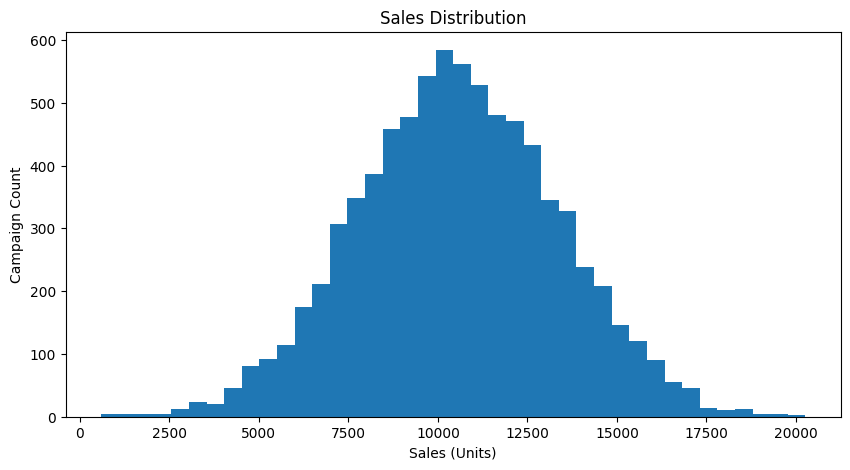

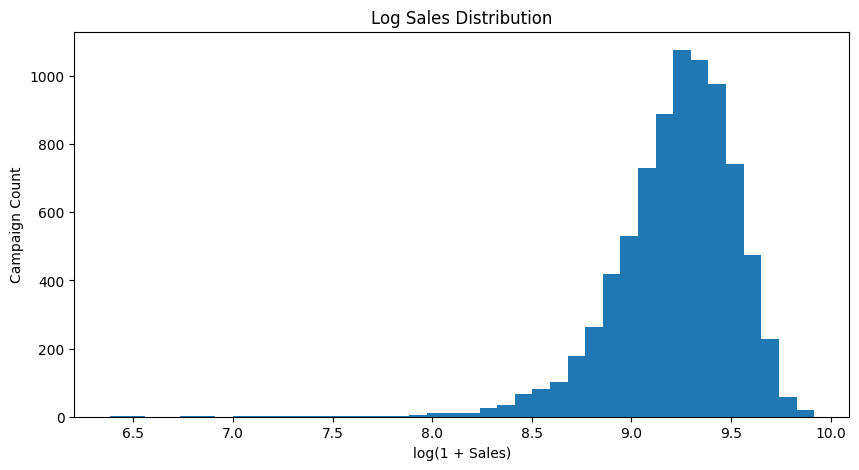

In [28]:
# Call the function
positive_sales = plot_sales_distribution(train, TARGET)

Observation
 - Sales values range approximately from 500 to 20,000 units.
 - Most campaigns generate sales between roughly 7,500 and 13,000 units.
 - The distribution is approximately bell-shaped, with a peak around 10,000–11,000 units.
 - Very low- and very high-sales campaigns are relatively uncommon.
Business insight

Most campaigns appear to generate sales within a fairly consistent middle range. Marketing teams should investigate the campaigns at both extremes to understand what differentiates unusually successful campaigns from underperforming ones.

Conclusion:
    Sales are concentrated around the middle of the observed range, with relatively few extreme outcomes.

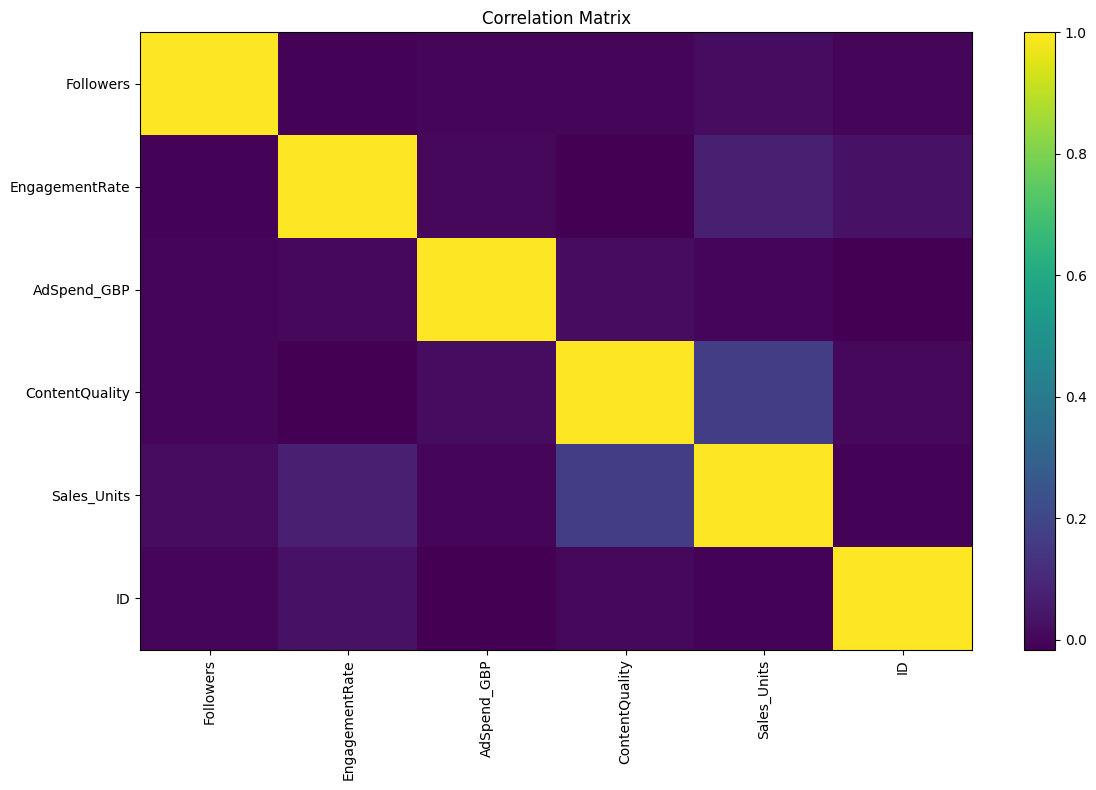

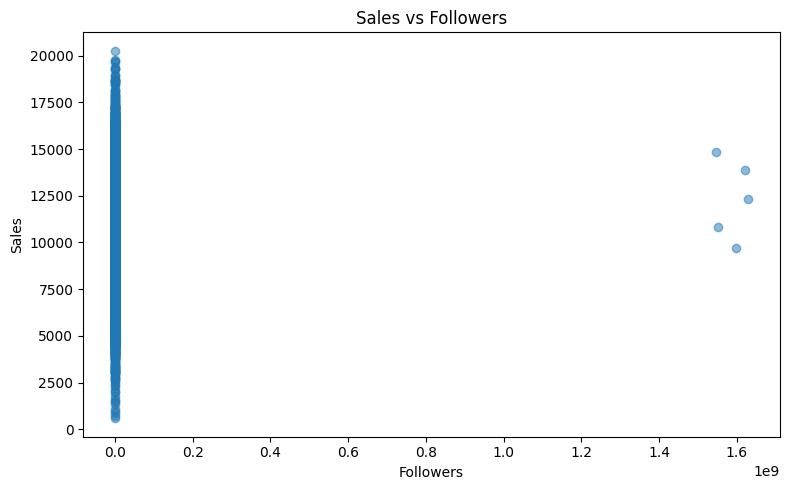

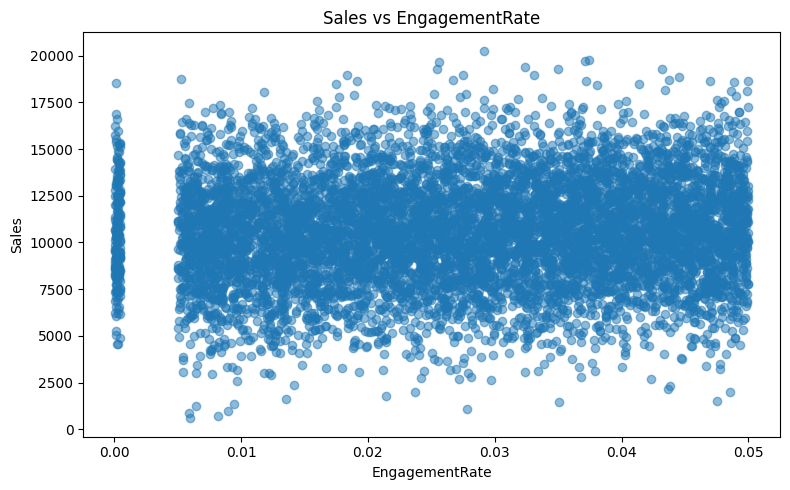

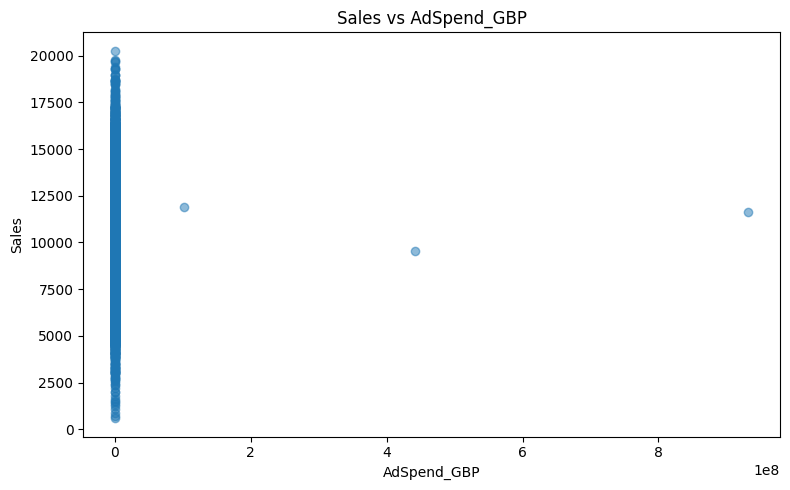

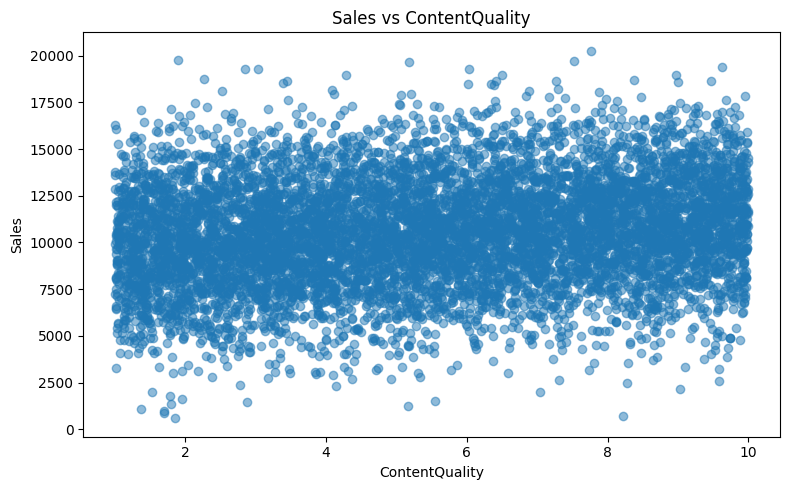

In [50]:
# plot_sales_distribution(train, TARGET) — understand the sales distribution.
feature_cols = [ FOLLOWERS_COL, ENGAGEMENT_COL, ADSPEND_COL, CONTENT_COL]
corr = analyze_correlations(
    train=train,
    target_col=TARGET,
    feature_cols=feature_cols
)

Sales vs. Ad Spend (GBP)

Observation
- Most campaigns have ad spend values concentrated near the left side of the chart.
- A few extremely large ad spend values extend the x-axis to hundreds of millions of GBP.
- Sales vary considerably among campaigns with similar, relatively small spend values.
- The few extreme-spend observations make the main relationship difficult to interpret.
Business insight
The dataset appears to contain potential ad-spend outliers. These could be data-entry errors, unusual campaigns, or genuine large-budget campaigns. Investigate them before drawing conclusions about advertising effectiveness.
Conclusion: This chart does not establish that higher ad spend causes higher sales. Check the extreme values and plot sales against a log-scaled spend axis or use spend bins to understand the relationship more clearly.

Compare high-performing vs. low-performing campaigns

Average Feature Values by Campaign Performance


Performance,Average Performing,High Performing,Low Performing
Followers,1.315036e+06,1.738187e+06,76821.907095
EngagementRate,2.706121e-02,2.842006e-02,0.025931
AdSpend_GBP,3.803512e+05,5.813057e+03,4234.331429
ContentQuality,5.522326e+00,6.030500e+00,4.901743


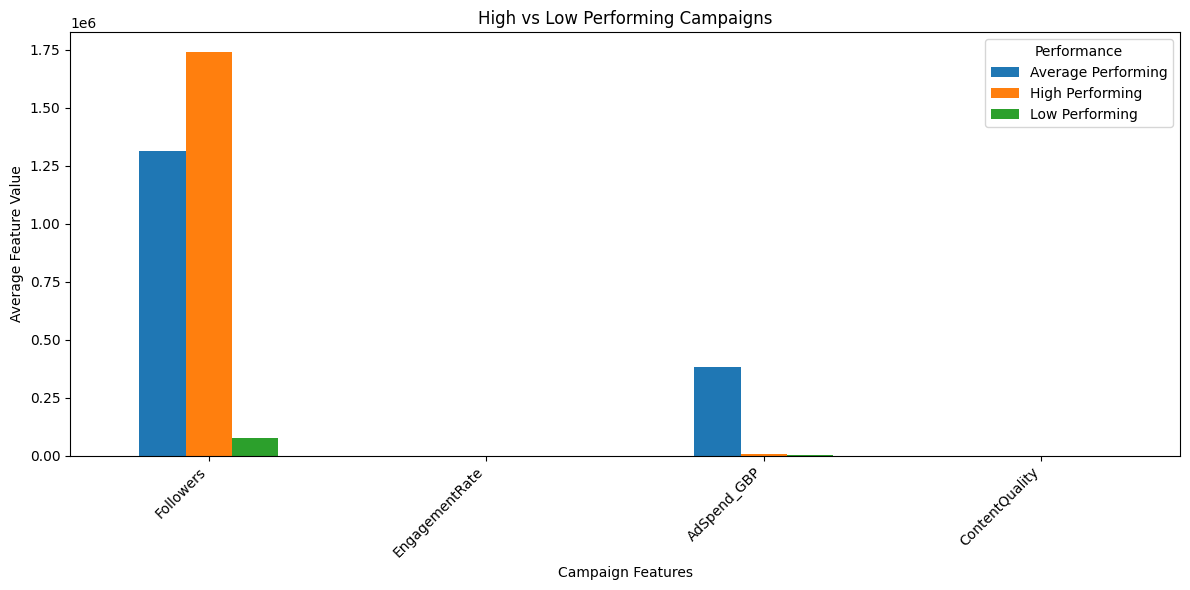

In [51]:
# Call the function
feature_cols = [FOLLOWERS_COL,ENGAGEMENT_COL,ADSPEND_COL,CONTENT_COL]

performance_comparison = compare_campaign_performance(
    train, TARGET, feature_cols
)

Observation
 - High-performing campaigns have substantially higher average follower counts than low-performing campaigns.
 - Average follower counts are approximately 1.74 million for high-performing campaigns, compared with around 80,000 for low-performing campaigns, based on the displayed chart's scale.
 - The engagement-rate and content-quality bars are difficult to interpret because the features may have different numerical scales.
 - The ad-spend values also appear strongly affected by extreme observations.

Business insight

Follower count may be associated with campaign performance, but reach alone does not establish influencer effectiveness. Compare engagement rates, content quality, cost per sale, and return on advertising spend separately.

Conclusion:  
 The chart suggests a potential relationship between follower count and sales. However, normalize features or use separate charts before comparing the relative importance of different campaign factors.

Analyze diminishing returns

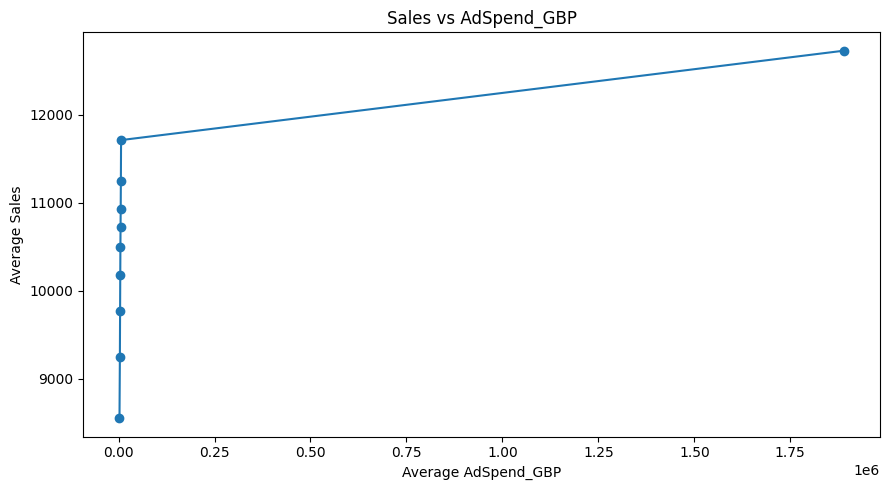

,Average_Feature,Average_Sales,Campaign_Count
Feature_Bin,,,
"(999.999, 3096.534]",2.426555e+03,8550.256378,784
"(3096.534, 3721.816]",3.426364e+03,9249.297194,784
"(3721.816, 4216.842]",3.980377e+03,9764.187500,784
"(4216.842, 4624.382]",4.428701e+03,10173.532567,783
"(4624.382, 5006.487]",4.816076e+03,10493.463010,784
"(5006.487, 5365.04]",5.183305e+03,10726.121173,784
"(5365.04, 5769.794]",5.562957e+03,10925.056194,783
"(5769.794, 6248.345]",6.004078e+03,11240.533163,784
"(6248.345, 6895.835]",6.547062e+03,11709.515306,784


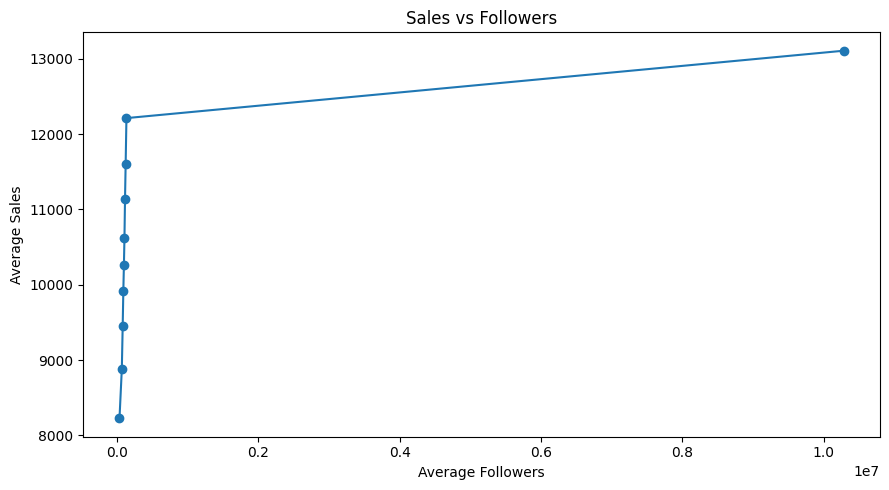

,Average_Feature,Average_Sales,Campaign_Count
Feature_Bin,,,
"(19.999, 57332.9]",3.279607e+04,8226.008929,784
"(57332.9, 72859.0]",6.589590e+04,8883.711735,784
"(72859.0, 82879.1]",7.805408e+04,9451.738520,784
"(82879.1, 91342.6]",8.712667e+04,9917.978316,784
"(91342.6, 99120.5]",9.525505e+04,10256.682398,784
"(99120.5, 106899.0]",1.031009e+05,10622.035714,784
"(106899.0, 115179.8]",1.110016e+05,11139.639031,784
"(115179.8, 124882.4]",1.198507e+05,11599.698980,784
"(124882.4, 138132.5]",1.311342e+05,12213.329082,784


In [52]:
# Analyze ad spend and influencer reach
adspend_analysis = plot_diminishing_returns(
    train, TARGET, ADSPEND_COL
)

followers_analysis = plot_diminishing_returns(
    train, TARGET, FOLLOWERS_COL
)

Sales vs. Ad Spend — Binned Average Analysis

Based on your first summary table:
Average ad-spend range	Average sales (units)
2,427	8,550
3,426	9,249
3,980	9,764
4,429	10,174
4,816	10,493
5,183	10,726
5,563	10,925
6,004	11,241
6,547	11,710
1,889,313	12,725

Observation

 - Average sales increase steadily across the first nine bins.
 - Sales rise from approximately 8,550 to 11,710 units across those bins.
 - The final bin contains an extreme average spend of approximately 1.89 million, making it incomparable to the preceding bins.
 - The last bin's average sales are approximately 12,725 units.

Business insight

The first nine bins suggest that higher spend is associated with higher average sales. However, the extreme final bin distorts the scale, and this pattern alone does not prove diminishing returns.
Conclusion: Investigate the extreme spending records and rerun the analysis after validating them. Then assess whether incremental sales gains decline as spending increases.

Sales vs. Followers — Binned Average Analysis

Based on your second summary table:
Average followers	Average sales (units)
32,796	8,226
65,896	8,884
78,054	9,452
87,127	9,918
95,254	10,257
103,101	10,622
111,002	11,140
119,851	11,600
131,134	12,213
10,286,830	13,108

Observation
 - Average sales increase from approximately 8,226 to 12,213 units across the first nine bins.
 - The final bin contains an extreme average follower count of approximately 10.29 million.
 - The final bin has average sales of approximately 13,108 units.
 - The general pattern suggests a positive association between influencer reach and sales.

Business insight

Influencers with larger audiences may help campaigns reach more potential customers. However, follower count alone is insufficient for influencer selection. Engagement, audience relevance, conversion rates, and campaign costs also matter.

Conclusion:  
 Follower count appears positively associated with sales in this dataset. Investigate extreme follower counts and compare influencers at similar audience sizes to identify more cost-effective opportunities.

**Detect sales outliers**

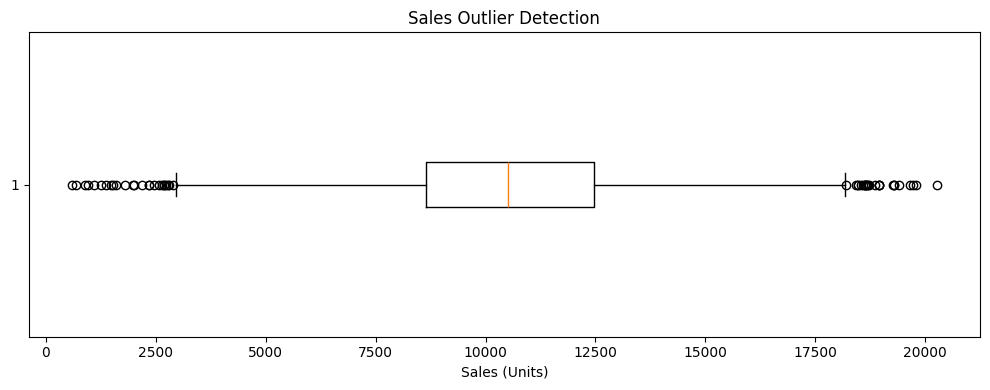

Total campaigns: 8000
Potential outliers: 50
Lower bound: 2917.125
Upper bound: 18184.125


In [54]:
#plot_sales_outliers(train, TARGET) — identify unusual campaigns.
sales_outliers = plot_sales_outliers(train, TARGET)

Sales Outlier Detection

Observation

 - The median sales value is approximately 10,500 units.
 - The middle 50% of campaigns generate approximately 8,600–12,500 units.
 - Several observations fall below the lower whisker, around 3,000 units.
 - Several observations exceed the upper whisker, around 18,200 units, with the highest close to 20,300 units.
 - The distribution contains outliers on both the lower and upper ends.

Business insight

 Low-sales outliers may indicate ineffective campaigns, poor audience targeting, or other campaign-specific issues. High-sales outliers may represent particularly successful campaigns or unusual conditions worth investigating.

 Conclusion:

 Sales outliers are present on both ends of the distribution. Investigate these campaigns to identify data-quality issues and understand the factors behind unusually low or high sales. Do not remove them automatically, because they may contain valuable business information.

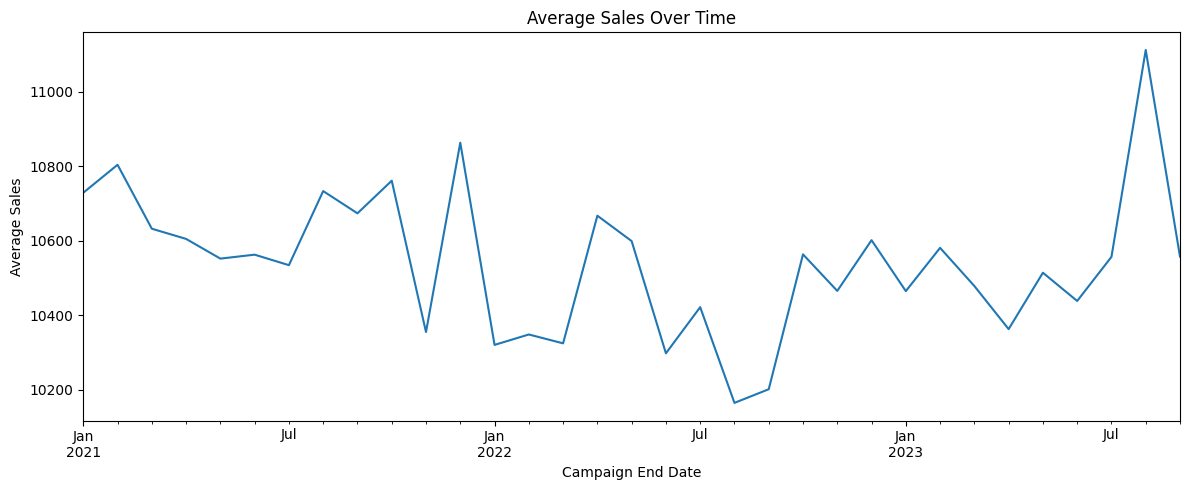

In [55]:
# plot_sales_over_time(train, TARGET, TIMESTAMP_COL) — investigate temporal trends.
monthly_sales = plot_sales_over_time(
    train=train,
    target_col=TARGET,
    timestamp_col=TIMESTAMP_COL
)

Average Sales Over Time

Observation
 - Monthly average sales fluctuate between approximately 10,170 and 11,110 units.
 - Sales remain relatively stable around 10,400–10,800 units for much of the period from January 2021 through October 2023.
 - A noticeable decline occurs around mid-to-late 2022, reaching approximately 10,170 units.
 - Sales recover afterward, with a sharp peak around August 2023 at approximately 11,110 units.
 - Sales decline again in the final month shown.

Business insight

Campaign sales show month-to-month variation rather than a consistent upward trend. The late-2022 decline and August 2023 peak are worth investigating for changes in influencer selection, engagement, advertising budgets, content quality, or seasonal demand.

Conclusion:   
  Average monthly sales are broadly stable over the observed period, with some noticeable fluctuations. Further investigation is needed to determine whether these changes are seasonal or associated with campaign strategy.

## **Overall EDA Findings**


## Consolidated EDA Findings

| Analysis | Key Observation | Business Implication |
|---|---|---|
| **Sales Distribution** | Most campaigns generate 7,500–13,000 units, with a peak around 10,000–11,000. | Typical campaign performance is concentrated within a relatively consistent range. |
| **Sales vs. Ad Spend** | Extreme spending values distort the scatter plot. Average sales increase across the first nine spend groups. | Validate extreme spending records before evaluating budget efficiency. |
| **Sales vs. Followers** | Average sales increase from approximately 8,226 to 12,213 units across the first nine follower-count groups. | Influencer reach may be associated with higher sales, but reach alone does not establish effectiveness. |
| **High- vs. Low-Performing Campaigns** | Follower counts differ substantially between performance groups. Other features are difficult to compare because of their different scales. | Investigate engagement, content quality, and cost efficiency separately. |
| **Diminishing Returns** | Sales increase across the observed bins, but extreme values distort the final groups. | Further analysis is needed to determine whether incremental gains decline as spend or reach increases. |
| **Sales Outliers** | Potential outliers exist below approximately 3,000 and above 18,200 units. | Investigate unusual campaigns and data quality before removing observations. |
| **Monthly Sales Trends** | Average sales fluctuate around 10,400–10,800 units for much of the period, peaking near 11,110 in August 2023. | Investigate seasonal effects and campaign changes rather than assuming sustained growth. |

### Overall Conclusion


 The EDA indicates that influencer reach and advertising spend may be associated with campaign sales. Sales remain relatively stable over time, with some fluctuations and potential outliers. Extreme values in sales, ad spend, and follower counts require further investigation. Additional analysis of engagement rate, content quality, and campaign costs will help identify effective marketing strategies and improve sales prediction.

# **Section C: Feature Engineering**


##  Feature Engineering

In [60]:
def add_features(df):
    df = df.copy()

    # 1. Convert campaign features to numeric safely
    numeric_cols = [
        FOLLOWERS_COL,
        ENGAGEMENT_COL,
        ADSPEND_COL,
        CONTENT_COL
    ]

    for col in numeric_cols:
        if col and col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # 2. Timestamp features
    if TIMESTAMP_COL and TIMESTAMP_COL in df.columns:
        dt = pd.to_datetime(df[TIMESTAMP_COL], errors="coerce")

        df["campaign_year"] = dt.dt.year
        df["campaign_month"] = dt.dt.month
        df["campaign_dayofweek"] = dt.dt.dayofweek
        df["campaign_quarter"] = dt.dt.quarter

        # Capture cyclical monthly patterns
        df["month_sin"] = np.sin(
            2 * np.pi * df["campaign_month"] / 12
        )
        df["month_cos"] = np.cos(
            2 * np.pi * df["campaign_month"] / 12
        )

    # 3. Log transformations
    if FOLLOWERS_COL and FOLLOWERS_COL in df.columns:
        df["log_followers"] = np.log1p(
            df[FOLLOWERS_COL].clip(lower=0)
        )

    if ADSPEND_COL and ADSPEND_COL in df.columns:
        df["log_ad_spend"] = np.log1p(
            df[ADSPEND_COL].clip(lower=0)
        )

    # 4. Estimated engaged audience
    if (
        FOLLOWERS_COL and ENGAGEMENT_COL
        and FOLLOWERS_COL in df.columns
        and ENGAGEMENT_COL in df.columns
    ):
        df["estimated_engaged_audience"] = (
            df[FOLLOWERS_COL] * df[ENGAGEMENT_COL]
        )

        df["log_engaged_audience"] = np.log1p(
            df["estimated_engaged_audience"].clip(lower=0)
        )

    # 5. Engagement × advertising spend
    if (
        ENGAGEMENT_COL and ADSPEND_COL
        and ENGAGEMENT_COL in df.columns
        and ADSPEND_COL in df.columns
    ):
        df["engagement_x_adspend"] = (
            df[ENGAGEMENT_COL] * df[ADSPEND_COL]
        )

    # 6. Spend and reach ratios
    if (
        FOLLOWERS_COL and ADSPEND_COL
        and FOLLOWERS_COL in df.columns
        and ADSPEND_COL in df.columns
    ):
        followers = df[FOLLOWERS_COL].replace(0, np.nan)
        spend = df[ADSPEND_COL].replace(0, np.nan)

        df["spend_per_follower"] = df[ADSPEND_COL] / followers
        df["followers_per_spend"] = df[FOLLOWERS_COL] / spend

    # 7. Content quality interactions
    if (
        CONTENT_COL and ENGAGEMENT_COL
        and CONTENT_COL in df.columns
        and ENGAGEMENT_COL in df.columns
    ):
        df["quality_x_engagement"] = (
            df[CONTENT_COL] * df[ENGAGEMENT_COL]
        )

    if (
        CONTENT_COL and ADSPEND_COL
        and CONTENT_COL in df.columns
        and ADSPEND_COL in df.columns
    ):
        df["quality_x_adspend"] = (
            df[CONTENT_COL] * df[ADSPEND_COL]
        )

    # Replace infinite values produced by extreme values or division
    df.replace([np.inf, -np.inf], np.nan, inplace=True)

    return df

## Apply Feature Engineering

In [62]:

# Apply identical feature engineering to train and test
train_fe = add_features(train)
test_fe = add_features(test)

# Separate target from training features
valid_target = train_fe[TARGET].notna()

X = train_fe.loc[valid_target].drop(
    columns=[TARGET], errors="ignore"
).copy()

y = pd.to_numeric(
    train_fe.loc[valid_target, TARGET],
    errors="coerce"
)

# Remove rows where the target is not numeric
valid_y = y.notna()
X = X.loc[valid_y].copy()
y = y.loc[valid_y].copy()

X_test = test_fe.drop(
    columns=[TARGET], errors="ignore"
).copy()

# Drop identifiers, notes, and raw timestamp
DROP_COLUMNS = [
    c for c in X.columns
    if c.lower() in {"id", "campaign_id", "record_id"}
    or "note" in c.lower()
    or (TIMESTAMP_COL and c == TIMESTAMP_COL)
]

X.drop(columns=DROP_COLUMNS, inplace=True, errors="ignore")
X_test.drop(columns=DROP_COLUMNS, inplace=True, errors="ignore")

# Ensure train and test have identical feature columns and order
X_test = X_test.reindex(columns=X.columns)

print("Dropped columns:", DROP_COLUMNS)
print("Training features:", X.shape[1])
print("Training rows:", X.shape[0])
print("Test rows:", X_test.shape[0])
print("Missing training features:", X.isna().sum().sum())
print("Missing test features:", X_test.isna().sum().sum())
print("Target shape:", y.shape)
print("Train/test feature columns aligned:",
      X.columns.equals(X_test.columns))


Dropped columns: ['ID', 'Timestamp', 'Notes']
Training features: 19
Training rows: 8000
Test rows: 2000
Missing training features: 3199
Missing test features: 829
Target shape: (8000,)
Train/test feature columns aligned: True


# **Section D: Model Building**

Goal :  Train a regression model that can predict sales from campaign attributes.


## Train/Validation Split and Preprocessing

In [64]:
def prepare_model_data(X, y, test_size=0.20, random_state=42):
    # 1. Validate target values
    y = pd.to_numeric(y, errors="coerce")
    valid_rows = y.notna()

    X = X.loc[valid_rows].copy()
    y = y.loc[valid_rows].copy()

    # 2. Split training and validation datasets
    X_train, X_valid, y_train, y_valid = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=random_state
    )

    # 3. Identify numeric and categorical features
    numeric_features = X_train.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_features = X_train.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    # 4. Numeric preprocessing
    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler())
    ])

    # 5. Categorical preprocessing
    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    # 6. Combine preprocessing steps
    preprocessor = ColumnTransformer([
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])

    # 7. Display dataset information
    print("Numeric features:", numeric_features)
    print("Categorical features:", categorical_features)
    print("Training shape:", X_train.shape)
    print("Validation shape:", X_valid.shape)
    print("Training target shape:", y_train.shape)
    print("Validation target shape:", y_valid.shape)

    return (
        X_train, X_valid, y_train, y_valid,
        preprocessor, numeric_features, categorical_features
    )


In [65]:
(
    X_train, X_valid, y_train, y_valid,
    preprocessor, numeric_features, categorical_features
) = prepare_model_data(X, y)

Numeric features: ['Followers', 'EngagementRate', 'AdSpend_GBP', 'ContentQuality', 'campaign_year', 'campaign_month', 'campaign_dayofweek', 'campaign_quarter', 'month_sin', 'month_cos', 'log_followers', 'log_ad_spend', 'estimated_engaged_audience', 'log_engaged_audience', 'engagement_x_adspend', 'spend_per_follower', 'followers_per_spend', 'quality_x_engagement', 'quality_x_adspend']
Categorical features: []
Training shape: (6400, 19)
Validation shape: (1600, 19)
Training target shape: (6400,)
Validation target shape: (1600,)


# **Section E: Model Evaluation & Tuning**

## Goal :  Evaluate how well your model performs and improve its reliability.


##  E1.Baseline

In [66]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

In [67]:
def evaluate_baseline(y_train, y_valid):
    # Predict the training target mean for every validation row
    baseline_pred = np.repeat(y_train.mean(), len(y_valid))

    # Calculate evaluation metrics
    baseline_rmse = np.sqrt(
        mean_squared_error(y_valid, baseline_pred)
    )
    baseline_mae = mean_absolute_error(y_valid, baseline_pred)
    baseline_r2 = r2_score(y_valid, baseline_pred)

    print(f"Baseline RMSE: {baseline_rmse:.4f}")
    print(f"Baseline MAE : {baseline_mae:.4f}")
    print(f"Baseline R²  : {baseline_r2:.4f}")

    return baseline_pred, {
        "Model": "Baseline",
        "RMSE": baseline_rmse,
        "MAE": baseline_mae,
        "R2": baseline_r2
    }


In [68]:
# Run baseline evaluation
baseline_pred, baseline_metrics = evaluate_baseline(
    y_train, y_valid
)

Baseline RMSE: 2820.1778
Baseline MAE : 2249.7002
Baseline R²  : -0.0009


In [72]:
baseline_rmse = baseline_metrics["RMSE"]
baseline_mae = baseline_metrics["MAE"]
baseline_r2 = baseline_metrics["R2"]

print(f"Baseline RMSE: {baseline_rmse:.4f}")
print(f"Baseline R²:   {baseline_r2:.4f}")
print(f"Baseline MAE : {baseline_mae:.4f}")

Baseline RMSE: 2820.1778
Baseline R²:   -0.0009
Baseline MAE : 2249.7002


##  E2.Model Comparison: Compare Ridge Regression, Random Forest, and Gradient Boosting against the baseline.

In [73]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(alpha=10.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=500,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=5,
        loss="huber",
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

In [74]:
def make_pipeline(model):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

In [75]:
model_results = []
fitted_models = {}

for name, estimator in models.items():

    print(f"Training: {name}")
    pipe = make_pipeline(estimator)
    pipe.fit(X_train, y_train)
    pred = np.maximum( pipe.predict(X_valid), 0 )

    # IMPORTANT:
    # Do NOT use squared=False.
    # Calculate RMSE manually.
    rmse = np.sqrt(mean_squared_error(y_valid, pred))
    mae = mean_absolute_error(y_valid,pred)
    r2 = r2_score(y_valid,pred)

    model_results.append({
        "Model": name,
        "Validation RMSE": rmse,
        "Validation MAE": mae,
        "Validation R2": r2
    })

    fitted_models[name] = pipe

comparison = pd.DataFrame(model_results).sort_values("Validation RMSE")

display(comparison)


Training: Linear Regression
Training: Ridge
Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting
Training: HistGradientBoosting


,Model,Validation RMSE,Validation MAE,Validation R2
4,Gradient Boosting,2081.579835,1667.759456,0.454688
3,Extra Trees,2113.720631,1686.386728,0.437718
2,Random Forest,2115.015564,1687.796707,0.437029
5,HistGradientBoosting,2120.150841,1703.483059,0.434292
1,Ridge,110717.755861,4734.742528,-1541.741655
0,Linear Regression,124845.776989,5087.826066,-1960.581559


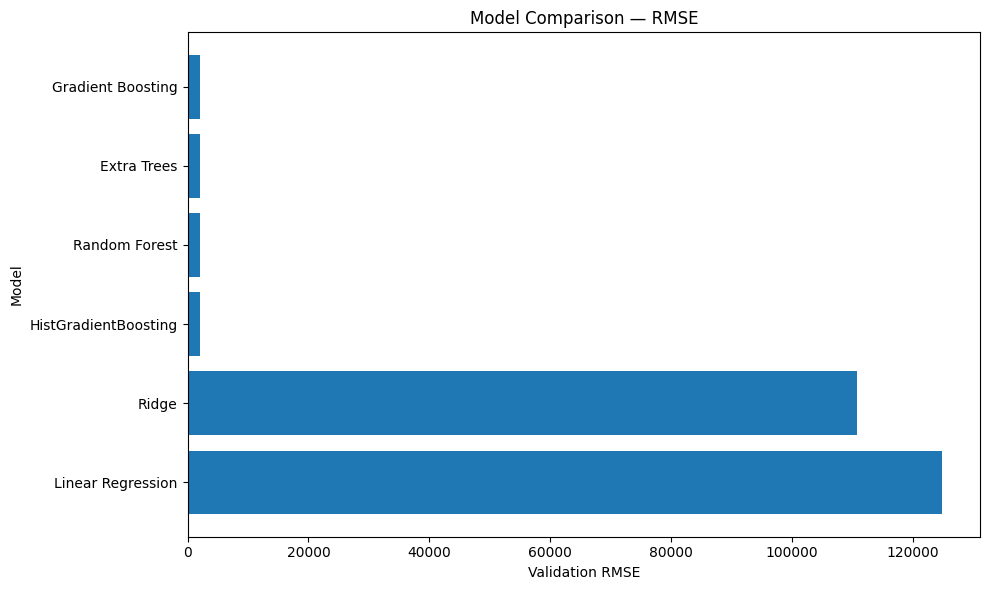

In [76]:
def plot_model_comparison(comparison):
    plot_df = comparison.sort_values(
        "Validation RMSE", ascending=True
    )

    plt.figure(figsize=(10, 6))
    plt.barh(
        plot_df["Model"],
        plot_df["Validation RMSE"]
    )

    plt.xlabel("Validation RMSE")
    plt.ylabel("Model")
    plt.title("Model Comparison — RMSE")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

# Call the function
plot_model_comparison(comparison)

       BEST SINGLE-SPLIT MODEL
Model           : Gradient Boosting
Validation RMSE : 2,081.58
Validation MAE  : 1,667.76
Validation R²   : 0.4547 (45.47%)


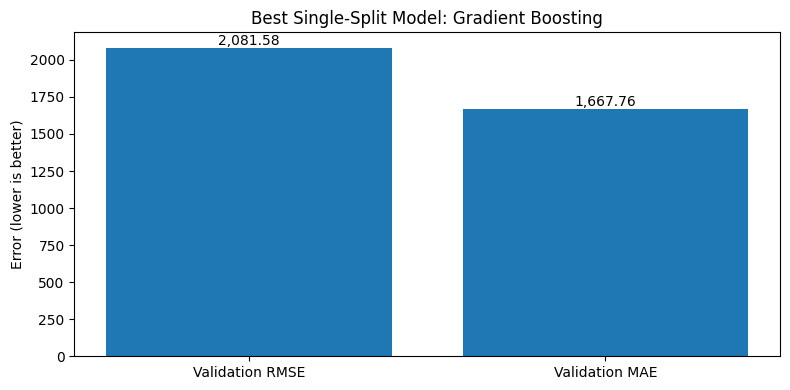

In [78]:
def display_best_model(comparison):
    # Pick the best model using the lowest validation RMSE
    best = comparison.sort_values("Validation RMSE").iloc[0]

    model_name = best["Model"]
    rmse = best["Validation RMSE"]
    mae = best["Validation MAE"]
    r2 = best["Validation R2"]

    print("=" * 50)
    print("       BEST SINGLE-SPLIT MODEL")
    print("=" * 50)
    print(f"Model           : {model_name}")
    print(f"Validation RMSE : {rmse:,.2f}")
    print(f"Validation MAE  : {mae:,.2f}")
    print(f"Validation R²   : {r2:.4f} ({r2 * 100:.2f}%)")
    print("=" * 50)

    # Plot error metrics from the selected model
    metrics = ["Validation RMSE", "Validation MAE"]
    values = [rmse, mae]

    plt.figure(figsize=(8, 4))
    bars = plt.bar(metrics, values)
    plt.title(f"Best Single-Split Model: {model_name}")
    plt.ylabel("Error (lower is better)")

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:,.2f}",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()

    return best

best_model_result = display_best_model(comparison)

## E3. Five-Fold Cross Validation

In [79]:
def evaluate_models_cv(models, X, y, preprocessor, n_splits=5):
    cv = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    cv_rows = []

    for name, estimator in models.items():
        print(f"Cross-validating: {name}")

        pipe = Pipeline([
            ("preprocessor", preprocessor),
            ("model", estimator)
        ])

        scores = cross_validate(
            pipe,
            X,
            y,
            cv=cv,
            scoring={
                "rmse": "neg_root_mean_squared_error",
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            },
            n_jobs=-1,
            error_score="raise"
        )

        cv_rows.append({
            "Model": name,
            "Mean CV RMSE": -scores["test_rmse"].mean(),
            "Std CV RMSE": scores["test_rmse"].std(),
            "Mean CV MAE": -scores["test_mae"].mean(),
            "Mean CV R2": scores["test_r2"].mean(),
            "Std CV R2": scores["test_r2"].std()
        })

    cv_results = (
        pd.DataFrame(cv_rows)
        .sort_values("Mean CV RMSE")
        .reset_index(drop=True)
    )

    display(cv_results)
    return cv_results


# Run five-fold cross-validation
cv_results = evaluate_models_cv(
    models=models,
    X=X_train,
    y=y_train,
    preprocessor=preprocessor,
    n_splits=5
)

Cross-validating: Linear Regression
Cross-validating: Ridge
Cross-validating: Random Forest
Cross-validating: Extra Trees
Cross-validating: Gradient Boosting
Cross-validating: HistGradientBoosting


,Model,Mean CV RMSE,Std CV RMSE,Mean CV MAE,Mean CV R2,Std CV R2
0,Gradient Boosting,2.026816e+03,2.144796e+01,1611.177614,4.770970e-01,1.557373e-02
1,Random Forest,2.054215e+03,1.624340e+01,1637.225811,4.629692e-01,1.061713e-02
2,Extra Trees,2.071122e+03,1.887880e+01,1652.849926,4.541303e-01,9.318931e-03
3,HistGradientBoosting,2.083380e+03,2.173177e+01,1663.101990,4.475640e-01,1.416247e-02
4,Ridge,5.513786e+06,9.920365e+06,157120.439866,-1.675657e+07,3.318717e+07
5,Linear Regression,6.149477e+06,1.112428e+07,175033.349898,-2.101750e+07,4.167020e+07


       INFLUENCER MARKETING - MODEL EVALUATION REPORT
Best Model             : Gradient Boosting
Mean CV RMSE           : 2,026.82
Std CV RMSE            : 21.45
Mean CV MAE            : 1,611.18
Mean CV R2             : 0.4771
Mean CV R2 (%)         : 47.71%


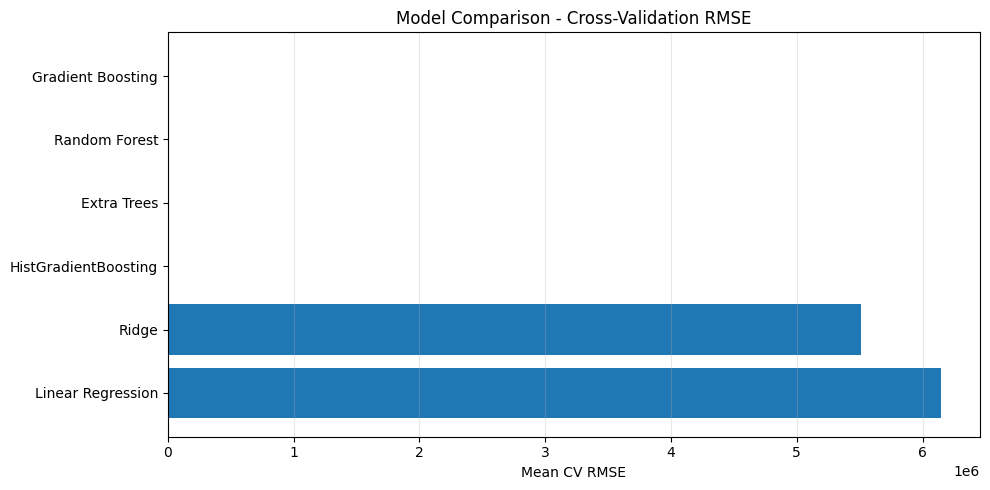

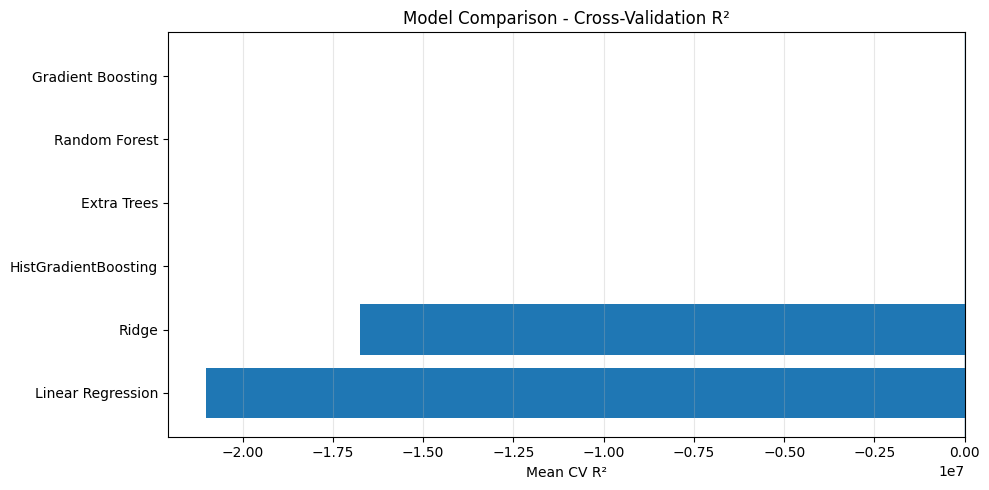

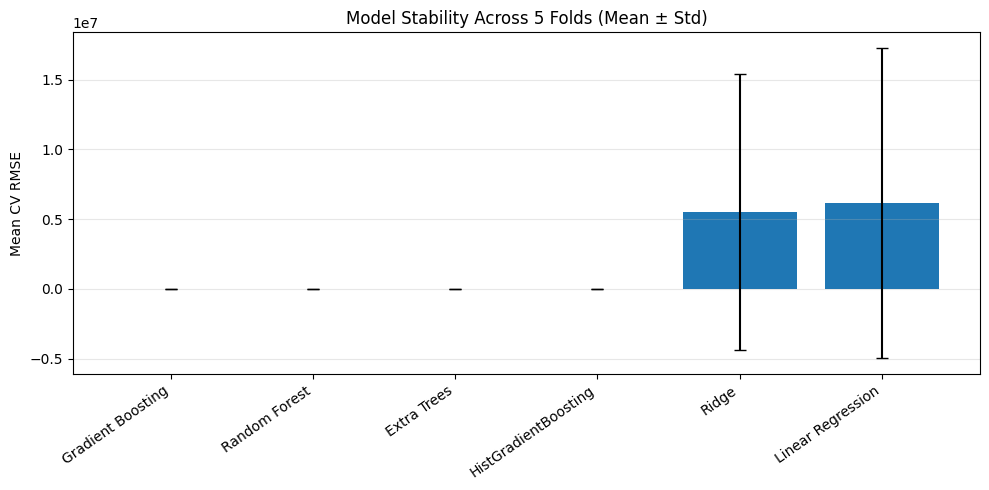

,Model,Mean CV RMSE,Std CV RMSE,Mean CV MAE,Mean CV R2,Std CV R2
0,Gradient Boosting,2.026816e+03,2.144796e+01,1611.177614,4.770970e-01,1.557373e-02
1,Random Forest,2.054215e+03,1.624340e+01,1637.225811,4.629692e-01,1.061713e-02
2,Extra Trees,2.071122e+03,1.887880e+01,1652.849926,4.541303e-01,9.318931e-03
3,HistGradientBoosting,2.083380e+03,2.173177e+01,1663.101990,4.475640e-01,1.416247e-02
4,Ridge,5.513786e+06,9.920365e+06,157120.439866,-1.675657e+07,3.318717e+07
5,Linear Regression,6.149477e+06,1.112428e+07,175033.349898,-2.101750e+07,4.167020e+07


In [80]:
def report_model_performance(cv_results):
    results = cv_results.copy()

    # Ensure the best model appears first
    results = results.sort_values("Mean CV RMSE").reset_index(drop=True)
    best = results.iloc[0]

    model_name = best["Model"]

    print("=" * 65)
    print("       INFLUENCER MARKETING - MODEL EVALUATION REPORT")
    print("=" * 65)
    print(f"Best Model             : {model_name}")
    print(f"Mean CV RMSE           : {best['Mean CV RMSE']:,.2f}")
    print(f"Std CV RMSE            : {best['Std CV RMSE']:,.2f}")
    print(f"Mean CV MAE            : {best['Mean CV MAE']:,.2f}")
    print(f"Mean CV R2             : {best['Mean CV R2']:.4f}")
    print(f"Mean CV R2 (%)         : {best['Mean CV R2'] * 100:.2f}%")
    print("=" * 65)

    # Chart 1: Compare RMSE (lower is better)
    plt.figure(figsize=(10, 5))
    plt.barh(results["Model"], results["Mean CV RMSE"])
    plt.gca().invert_yaxis()
    plt.xlabel("Mean CV RMSE")
    plt.title("Model Comparison - Cross-Validation RMSE")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Chart 2: Compare R² (higher is better)
    plt.figure(figsize=(10, 5))
    plt.barh(results["Model"], results["Mean CV R2"])
    plt.gca().invert_yaxis()
    plt.axvline(0, linewidth=1)
    plt.xlabel("Mean CV R²")
    plt.title("Model Comparison - Cross-Validation R²")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Chart 3: RMSE stability across folds
    plt.figure(figsize=(10, 5))
    plt.bar(
        results["Model"],
        results["Mean CV RMSE"],
        yerr=results["Std CV RMSE"],
        capsize=4
    )
    plt.ylabel("Mean CV RMSE")
    plt.title("Model Stability Across 5 Folds (Mean ± Std)")
    plt.xticks(rotation=35, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Display the complete comparison table
    display(results)

    return results

cv_report = report_model_performance(cv_results)

MODEL EVALUATION REPORT
---------------------------------------------
Best model  : Gradient Boosting
Mean RMSE   : 2,026.82
Std RMSE    : 21.45
Mean MAE    : 1,611.18
Mean R²     : 0.4771
---------------------------------------------


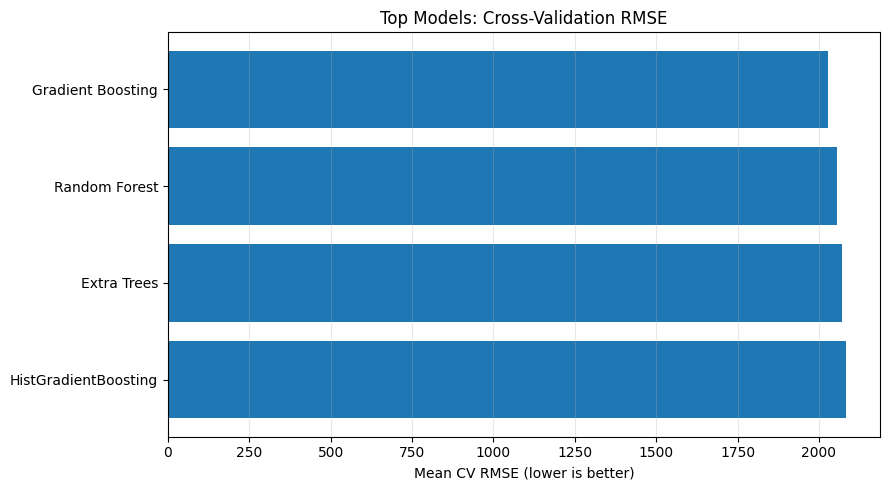

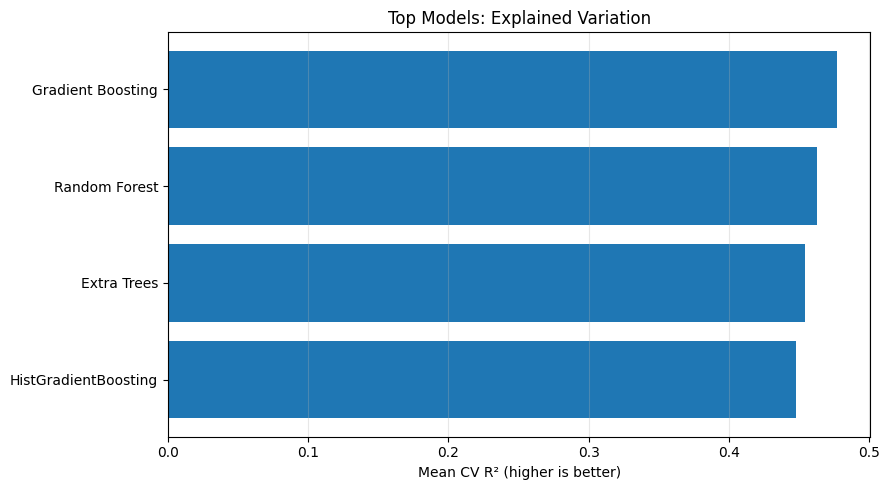

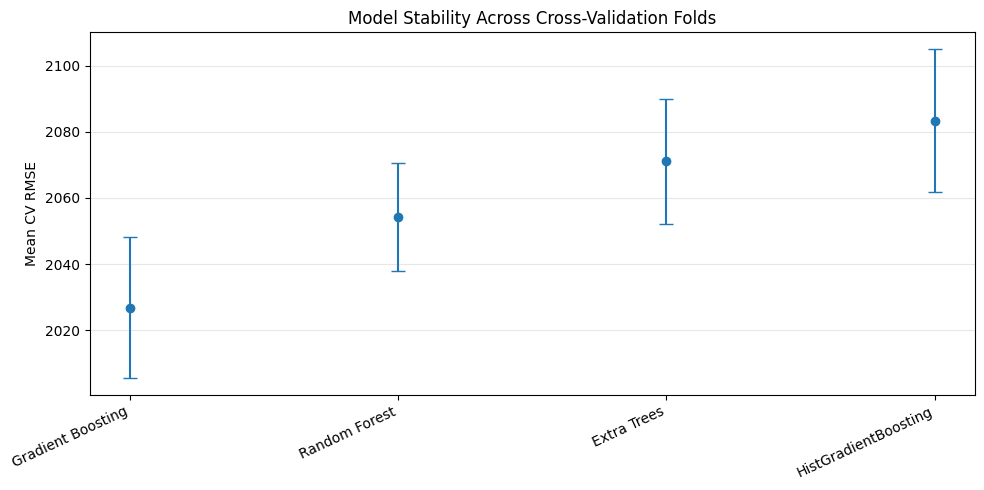

,Model,Mean CV RMSE,Std CV RMSE,Mean CV MAE,Mean CV R2,Std CV R2
0,Gradient Boosting,"2,026.82",21.45,"1,611.18",0.4771,0.0156
1,Random Forest,"2,054.21",16.24,"1,637.23",0.4630,0.0106
2,Extra Trees,"2,071.12",18.88,"1,652.85",0.4541,0.0093
3,HistGradientBoosting,"2,083.38",21.73,"1,663.10",0.4476,0.0142
4,Ridge,"5,513,786.00","9,920,365.18","157,120.44",-16756574.7799,33187167.5719
5,Linear Regression,"6,149,476.69","11,124,283.77","175,033.35",-21017497.8575,41670195.1307


In [81]:
def plot_cv_report(cv_results):
    results = cv_results.copy()
    results = results.sort_values("Mean CV RMSE").reset_index(drop=True)

    best = results.iloc[0]

    print("MODEL EVALUATION REPORT")
    print("-" * 45)
    print(f"Best model  : {best['Model']}")
    print(f"Mean RMSE   : {best['Mean CV RMSE']:,.2f}")
    print(f"Std RMSE    : {best['Std CV RMSE']:,.2f}")
    print(f"Mean MAE    : {best['Mean CV MAE']:,.2f}")
    print(f"Mean R²     : {best['Mean CV R2']:.4f}")
    print("-" * 45)

    # Exclude unstable linear models from the main comparison chart
    # so the useful differences between tree models remain visible.
    tree_results = results[
        results["Model"].isin([
            "Gradient Boosting",
            "Random Forest",
            "Extra Trees",
            "HistGradientBoosting"
        ])
    ]

    # 1. RMSE comparison
    plt.figure(figsize=(9, 5))
    plt.barh(tree_results["Model"], tree_results["Mean CV RMSE"])
    plt.gca().invert_yaxis()
    plt.xlabel("Mean CV RMSE (lower is better)")
    plt.title("Top Models: Cross-Validation RMSE")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # 2. R² comparison
    plt.figure(figsize=(9, 5))
    plt.barh(tree_results["Model"], tree_results["Mean CV R2"])
    plt.gca().invert_yaxis()
    plt.xlabel("Mean CV R² (higher is better)")
    plt.title("Top Models: Explained Variation")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # 3. RMSE variability
    plt.figure(figsize=(10, 5))
    plt.errorbar(
        tree_results["Model"],
        tree_results["Mean CV RMSE"],
        yerr=tree_results["Std CV RMSE"],
        fmt="o",
        capsize=5
    )
    plt.ylabel("Mean CV RMSE")
    plt.title("Model Stability Across Cross-Validation Folds")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Display all metrics, including unstable models
    display(
        results.style.format({
            "Mean CV RMSE": "{:,.2f}",
            "Std CV RMSE": "{:,.2f}",
            "Mean CV MAE": "{:,.2f}",
            "Mean CV R2": "{:.4f}",
            "Std CV R2": "{:.4f}"
        })
    )

    return results

cv_report = plot_cv_report(cv_results)

## E4. Hyperparameter Tuning — Random Forest

In [82]:
def tune_models(
    X_train,
    y_train,
    X_valid,
    y_valid,
    preprocessor,
    n_iter=30,
    cv=5,
    random_state=42,
    n_jobs=-1
):
    from sklearn.model_selection import KFold
    from sklearn.pipeline import Pipeline

    cv_strategy = (
        cv if not isinstance(cv, int)
        else KFold(
            n_splits=cv,
            shuffle=True,
            random_state=random_state
        )
    )

    pipelines = {
        "Random Forest": Pipeline([
            ("preprocessor", preprocessor),
            ("model", RandomForestRegressor(
                random_state=random_state,
                n_jobs=1
            ))
        ]),
        "Gradient Boosting": Pipeline([
            ("preprocessor", preprocessor),
            ("model", GradientBoostingRegressor(
                random_state=random_state
            ))
        ])
    }

    param_grids = {
        "Random Forest": {
            "model__n_estimators": [300, 500, 800],
            "model__max_depth": [None, 8, 12, 20, 30],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4, 8],
            "model__max_features": ["sqrt", "log2", 0.7, 1.0]
        },
        "Gradient Boosting": {
            "model__n_estimators": [100, 200, 300, 500],
            "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
            "model__max_depth": [2, 3, 4, 5],
            "model__min_samples_leaf": [2, 5, 10, 20],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__loss": ["squared_error", "huber"]
        }
    }

    searches = {}
    results = []

    for name, pipeline in pipelines.items():
        print(f"\nTuning {name}...")

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=param_grids[name],
            n_iter=n_iter,
            scoring="neg_root_mean_squared_error",
            cv=cv_strategy,
            random_state=random_state,
            n_jobs=n_jobs,
            verbose=1,
            refit=True,
            error_score="raise"
        )

        search.fit(X_train, y_train)
        searches[name] = search

        predictions = np.maximum(
            search.best_estimator_.predict(X_valid), 0
        )

        results.append({
            "Model": name,
            "Best CV RMSE": -search.best_score_,
            "Validation RMSE": np.sqrt(
                mean_squared_error(y_valid, predictions)
            ),
            "Validation MAE": mean_absolute_error(
                y_valid, predictions
            ),
            "Validation R2": r2_score(y_valid, predictions),
            "Best Parameters": search.best_params_
        })

        print(f"Best CV RMSE: {-search.best_score_:,.2f}")
        print(f"Best parameters: {search.best_params_}")

    results_df = (
        pd.DataFrame(results)
        .sort_values("Validation RMSE")
        .reset_index(drop=True)
    )

    print("\nTUNED MODEL COMPARISON")
    display(results_df)

    best_name = results_df.iloc[0]["Model"]
    best_search = searches[best_name]

    print(f"\nBest validation model: {best_name}")

    return searches, results_df, best_search


## E5. Apply Hyperparameter Tuning — Gradient Boosting and Random Forest

In [83]:
searches, tuned_results, best_search = tune_models(
    X_train=X_train,
    y_train=y_train,
    X_valid=X_valid,
    y_valid=y_valid,
    preprocessor=preprocessor,
    n_iter=30,
    cv=5
)


Tuning Random Forest...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV RMSE: 2,041.07
Best parameters: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 8}

Tuning Gradient Boosting...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV RMSE: 2,022.90
Best parameters: {'model__subsample': 0.85, 'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_depth': 2, 'model__loss': 'huber', 'model__learning_rate': 0.1}

TUNED MODEL COMPARISON


,Model,Best CV RMSE,Validation RMSE,Validation MAE,Validation R2,Best Parameters
0,Gradient Boosting,2022.896016,2087.588632,1668.063211,0.451536,"{'model__subsample': 0.85, 'model__n_estimator..."
1,Random Forest,2041.068985,2101.426403,1675.992857,0.444240,"{'model__n_estimators': 500, 'model__min_sampl..."



Best validation model: Gradient Boosting


In [89]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

def plot_regression_diagnostics(y_valid, valid_pred):
    actual = np.asarray(y_valid).ravel()
    predicted = np.asarray(valid_pred).ravel()

    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted lengths do not match.")

    residuals = actual - predicted

    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    print("REGRESSION DIAGNOSTICS")
    print("-" * 35)
    print(f"R²   : {r2:.4f}")
    print(f"RMSE : {rmse:,.2f}")
    print(f"MAE  : {mae:,.2f}")

    # 1. Actual vs Predicted
    lo = min(actual.min(), predicted.min())
    hi = max(actual.max(), predicted.max())

    plt.figure(figsize=(8, 8))
    plt.scatter(actual, predicted, alpha=0.6)
    plt.plot([lo, hi], [lo, hi], linestyle="--")
    plt.xlabel("Actual Sales")
    plt.ylabel("Predicted Sales")
    plt.title(f"Actual vs Predicted — R² = {r2:.3f}")
    plt.tight_layout()
    plt.show()

    # 2. Residuals vs Predicted
    plt.figure(figsize=(10, 5))
    plt.scatter(predicted, residuals, alpha=0.6)
    plt.axhline(0, linestyle="--")
    plt.xlabel("Predicted Sales")
    plt.ylabel("Residual (Actual - Predicted)")
    plt.title("Residuals vs Predicted")
    plt.tight_layout()
    plt.show()

    # 3. Residual distribution
    plt.figure(figsize=(10, 5))
    plt.hist(residuals, bins=40)
    plt.xlabel("Residual (Actual - Predicted)")
    plt.ylabel("Frequency")
    plt.title("Residual Distribution")
    plt.tight_layout()
    plt.show()

    return {
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae,
        "residuals": residuals
    }


REGRESSION DIAGNOSTICS
-----------------------------------
R²   : 0.4515
RMSE : 2,087.59
MAE  : 1,668.06


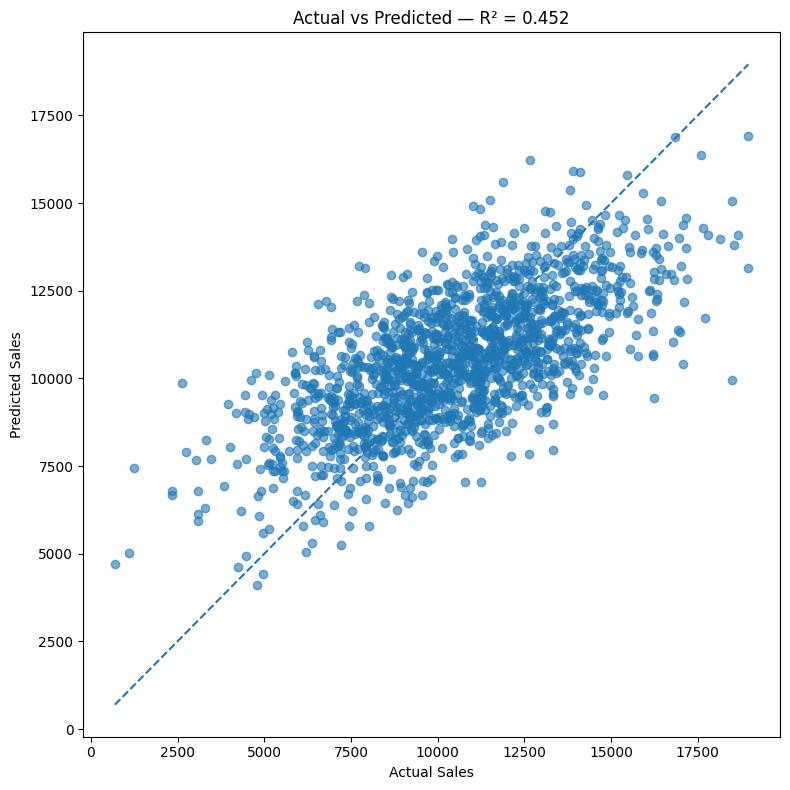

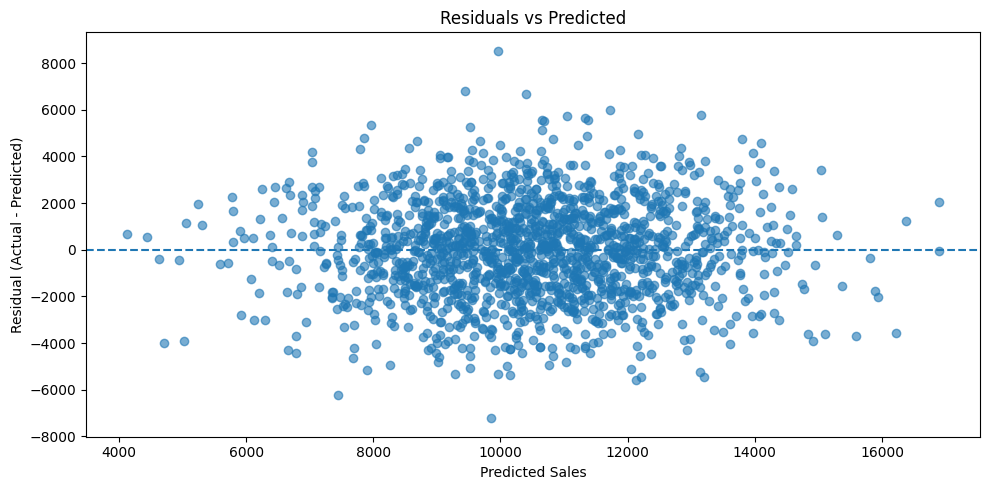

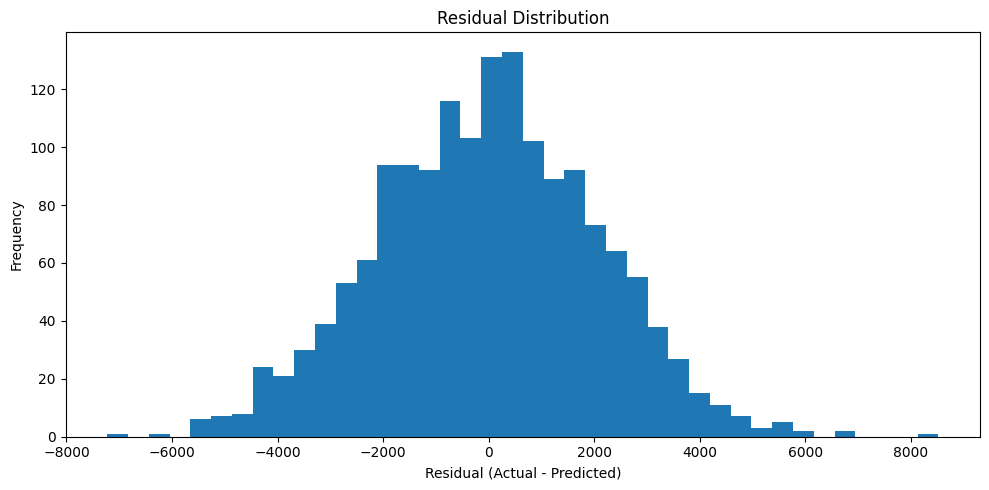

In [90]:
final_model = best_search.best_estimator_

valid_pred = np.maximum(
    final_model.predict(X_valid), 0
)

diagnostics = plot_regression_diagnostics(
    y_valid=y_valid,
    valid_pred=valid_pred
)

## E6.Feature importance

In [183]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

def analyze_feature_importance(
    model, X_valid, y_valid, n_repeats=5
):
    result = permutation_importance(
        model,
        X_valid,
        y_valid,
        scoring="neg_root_mean_squared_error",
        n_repeats=n_repeats,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X_valid.columns,
        "Importance": result.importances_mean,
        "Std": result.importances_std
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(15))

    top = importance_df.head(15).sort_values("Importance")

    plt.figure(figsize=(10, 6))
    plt.barh(
        top["Feature"],
        top["Importance"],
        xerr=top["Std"]
    )
    plt.xlabel("Increase in RMSE when feature is shuffled")
    plt.title("Top 15 Features — Gradient Boosting")
    plt.tight_layout()
    plt.show()

    return importance_df


,Feature,Importance,Std
0,Followers,352.813414,33.350954
10,log_followers,130.906738,22.015391
18,quality_x_adspend,97.416885,6.652844
11,log_ad_spend,85.430315,11.000431
2,AdSpend_GBP,85.141129,10.284327
15,spend_per_follower,21.347492,1.917890
16,followers_per_spend,10.803470,0.832215
14,engagement_x_adspend,9.387594,3.447082
12,estimated_engaged_audience,1.571257,0.693753
13,log_engaged_audience,0.917204,0.517643


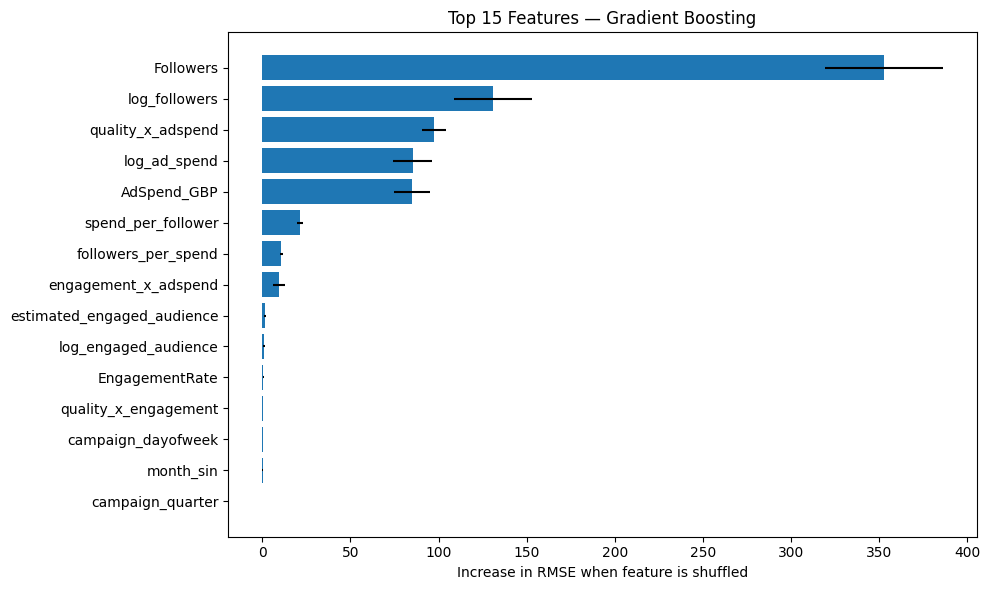

In [184]:
final_model = best_search.best_estimator_

feature_importance = analyze_feature_importance(
    model=final_model,
    X_valid=X_valid,
    y_valid=y_valid
)

# **Section F: Business Insights & Pipeline Design**

Goal -
Translate model results into actionable insights and design a solution that can be reused.


## F1: Business Insights

In [185]:
def generate_business_insights(feature_importance, top_n=10):
    top_features = (
        feature_importance
        .sort_values("Importance", ascending=False)
        .head(top_n)
        .copy()
    )

    print("=" * 65)
    print("BUSINESS INSIGHTS: INFLUENCER MARKETING")
    print("=" * 65)

    for rank, (_, row) in enumerate(top_features.iterrows(), start=1):
        feature = row["Feature"]
        importance = row["Importance"]

        print(f"{rank}. {feature}")
        print(f"   Importance: {importance:.4f}")

        if importance > 0:
            print(
                "   Insight: Shuffling this feature increased prediction "
                "error, suggesting it contains useful predictive information."
            )
        else:
            print(
                "   Insight: This feature did not improve validation "
                "performance reliably in this analysis."
            )

    print("\nBUSINESS RECOMMENDATIONS")
    print("-" * 65)
    print("1. Use predicted sales to compare proposed campaigns.")
    print("2. Compare predicted sales with campaign costs and expected profit.")
    print("3. Prioritize influential features when planning campaigns.")
    print("4. Monitor actual versus predicted sales after each campaign.")
    print("5. Validate predictions on new campaigns before making "
          "large budget decisions.")

    return top_features


top_business_features = generate_business_insights(
    feature_importance,
    top_n=10
)


BUSINESS INSIGHTS: INFLUENCER MARKETING
1. Followers
   Importance: 352.8134
   Insight: Shuffling this feature increased prediction error, suggesting it contains useful predictive information.
2. log_followers
   Importance: 130.9067
   Insight: Shuffling this feature increased prediction error, suggesting it contains useful predictive information.
3. quality_x_adspend
   Importance: 97.4169
   Insight: Shuffling this feature increased prediction error, suggesting it contains useful predictive information.
4. log_ad_spend
   Importance: 85.4303
   Insight: Shuffling this feature increased prediction error, suggesting it contains useful predictive information.
5. AdSpend_GBP
   Importance: 85.1411
   Insight: Shuffling this feature increased prediction error, suggesting it contains useful predictive information.
6. spend_per_follower
   Importance: 21.3475
   Insight: Shuffling this feature increased prediction error, suggesting it contains useful predictive information.
7. followers_p

## F2. Train on Full Training Data and Predict Test

In [186]:
import json
import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone


def train_final_model(
    best_search,
    X,
    y,
    X_test,
    test_raw,
    target,
    final_model_name,
    final_rmse,
    final_mae,
    final_r2
):
    # Output paths
    SUBMISSION_PATH = "/content/submission.csv"
    MODEL_PATH = "/content/influencer_sales_model.pkl"
    METRICS_PATH = "/content/model_metrics.csv"
    METADATA_PATH = "/content/model_metadata.json"

    # 1. Retrain selected model on all labeled training data
    final_model = clone(best_search.best_estimator_)
    final_model.fit(X, y)

    # 2. Align test features
    X_test_final = X_test.reindex(
        columns=X.columns,
        fill_value=np.nan
    )

    # 3. Generate predictions
    test_pred = np.maximum(
        final_model.predict(X_test_final),
        0
    )

    # 4. Build submission
    submission = pd.DataFrame({target: test_pred})

    # Preserve identifier, if present
    id_cols = [
        c for c in test_raw.columns
        if c.lower() in {"id", "campaign_id", "record_id"}
    ]

    if id_cols:
        submission.insert(
            0, id_cols[0], test_raw[id_cols[0]].values
        )

    # 5. Validate predictions
    assert len(submission) == len(test_raw)
    assert submission[target].notna().all()
    assert np.isfinite(submission[target]).all()
    assert (submission[target] >= 0).all()

    # 6. Save submission and model
    submission.to_csv(SUBMISSION_PATH, index=False)
    joblib.dump(final_model, MODEL_PATH)

    # 7. Save evaluation metrics
    best_cv_rmse = float(-best_search.best_score_)

    metrics = pd.DataFrame([{
        "model": final_model_name,
        "holdout_rmse": float(final_rmse),
        "holdout_mae": float(final_mae),
        "holdout_r2": float(final_r2),
        "best_cv_rmse": best_cv_rmse
    }])

    metrics.to_csv(METRICS_PATH, index=False)

    # 8. Save metadata
    metadata = {
        "target": target,
        "followers_column": FOLLOWERS_COL,
        "engagement_column": ENGAGEMENT_COL,
        "ad_spend_column": ADSPEND_COL,
        "content_quality_column": CONTENT_COL,
        "timestamp_column": TIMESTAMP_COL,
        "model_name": final_model_name,
        "feature_columns": X.columns.tolist(),
        "holdout_rmse": float(final_rmse),
        "holdout_mae": float(final_mae),
        "holdout_r2": float(final_r2),
        "best_cv_rmse": best_cv_rmse
    }

    with open(METADATA_PATH, "w") as f:
        json.dump(metadata, f, indent=2)

    # 9. Display results
    display(submission.head(20))

    print("Prediction rows:", len(submission))
    print("Mean predicted sales:", round(submission[target].mean(), 2))
    print("\nSaved successfully:")
    print(SUBMISSION_PATH)
    print(MODEL_PATH)
    print(METRICS_PATH)
    print(METADATA_PATH)


    return final_model, submission, metrics, metadata

In [187]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Train on training split only
final_model_holdout = clone(best_search.best_estimator_)
final_model_holdout.fit(X_train, y_train)

# Evaluate on validation split
valid_predictions = np.asarray(
    final_model_holdout.predict(X_valid),
    dtype=float
)

if not np.isfinite(valid_predictions).all():
    raise ValueError("Validation predictions contain invalid values.")


# Sales cannot be negative
valid_predictions = np.maximum(valid_predictions, 0)

final_rmse = np.sqrt(
    mean_squared_error(y_valid, valid_predictions)
)
final_mae = mean_absolute_error(y_valid, valid_predictions)
final_r2 = r2_score(y_valid, valid_predictions)

#final_model_name = type(final_model_holdout).__name__
final_model_name = tuned_results.iloc[0]["Model"]

print("=" * 45)
print("HOLDOUT MODEL EVALUATION")
print("=" * 45)
print(f"Model : {final_model_name}")
print(f"RMSE  : {final_rmse:,.2f}")
print(f"MAE   : {final_mae:,.2f}")
print(f"R²    : {final_r2:.4f}")

HOLDOUT MODEL EVALUATION
Model : Gradient Boosting
RMSE  : 2,087.59
MAE   : 1,668.06
R²    : 0.4515


In [188]:
final_model, submission, metrics, metadata = train_final_model(
    best_search=best_search,
    X=X,
    y=y,
    X_test=X_test,
    test_raw=test_raw,
    target=TARGET,
    final_model_name=final_model_name,
    final_rmse=final_rmse,
    final_mae=final_mae,
    final_r2=final_r2
)

,ID,Sales_Units
0,6252,12701.557058
1,4684,8591.256367
2,1731,10454.710030
3,4742,10744.207593
4,4521,11594.678518
5,6340,9239.104277
6,576,10866.894718
7,5202,11513.483102
8,6363,12788.284729
9,439,12989.101269


Prediction rows: 2000
Mean predicted sales: 10479.7

Saved successfully:
/content/submission.csv
/content/influencer_sales_model.pkl
/content/model_metrics.csv
/content/model_metadata.json


In [189]:
def validate_predictions(submission, X_test, target_col):
    print("=" * 55)
    print("       INFLUENCER SALES — PREDICTION VALIDATION")
    print("=" * 55)

    # 1. Validate input structure
    required_columns = [target_col]
    missing_columns = [
        col for col in required_columns
        if col not in submission.columns
    ]

    checks = {}

    checks["Prediction column exists"] = len(missing_columns) == 0

    if missing_columns:
        print(f"\nFAIL: Missing columns: {missing_columns}")
        return False

    predictions = submission[target_col]

    # 2. Validate row count and index alignment
    checks["Test row count matches"] = (
        len(submission) == len(X_test)
    )

    # 3. Validate predictions
    checks["No missing predictions"] = (
        predictions.notna().all()
    )

    numeric_predictions = pd.to_numeric(
        predictions, errors="coerce"
    )

    checks["All predictions are numeric"] = (
        numeric_predictions.notna().all()
    )

    checks["No infinite predictions"] = (
        np.isfinite(numeric_predictions.to_numpy(dtype=float)).all()
    )

    checks["No negative predictions"] = (
        (numeric_predictions >= 0).all()
    )

    checks["Prediction count is greater than zero"] = (
        len(numeric_predictions) > 0
    )

    # 4. Display validation results
    print("\nVALIDATION CHECKS")
    print("-" * 55)

    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}: {name}")

    all_passed = all(checks.values())

    # 5. Show prediction statistics only when valid
    if all_passed:
        print("\nPREDICTION SUMMARY")
        print("-" * 55)
        print(f"Test rows          : {len(X_test):,}")
        print(f"Predictions        : {len(numeric_predictions):,}")
        print(f"Mean sales         : {numeric_predictions.mean():,.2f}")
        print(f"Median sales       : {numeric_predictions.median():,.2f}")
        print(f"Minimum sales      : {numeric_predictions.min():,.2f}")
        print(f"Maximum sales      : {numeric_predictions.max():,.2f}")

        print("\nSAMPLE PREDICTIONS")
        display(submission.head(10))

        print("\nRESULT: All prediction validation checks passed.")
    else:
        print("\nRESULT: Validation failed. Fix the failed checks.")

    print("=" * 55)
    return all_passed


# Run validation against your generated test submission
predictions_valid = validate_predictions(
    submission=submission,
    X_test=X_test,
    target_col=TARGET
)

assert predictions_valid, (
    "Prediction validation failed. "
    "Check the failed validation items above."
)


       INFLUENCER SALES — PREDICTION VALIDATION

VALIDATION CHECKS
-------------------------------------------------------
PASS: Prediction column exists
PASS: Test row count matches
PASS: No missing predictions
PASS: All predictions are numeric
PASS: No infinite predictions
PASS: No negative predictions
PASS: Prediction count is greater than zero

PREDICTION SUMMARY
-------------------------------------------------------
Test rows          : 2,000
Predictions        : 2,000
Mean sales         : 10,479.70
Median sales       : 10,468.47
Minimum sales      : 5,274.28
Maximum sales      : 16,162.32

SAMPLE PREDICTIONS


,ID,Sales_Units
0,6252,12701.557058
1,4684,8591.256367
2,1731,10454.710030
3,4742,10744.207593
4,4521,11594.678518
5,6340,9239.104277
6,576,10866.894718
7,5202,11513.483102
8,6363,12788.284729
9,439,12989.101269



RESULT: All prediction validation checks passed.


resuable pipeline

In [190]:
def prepare_future_campaign_data(raw_df):
    if not isinstance(raw_df, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    if raw_df.empty:
        raise ValueError("Input campaign data is empty.")

    df = raw_df.copy()
    df.columns = [normalize_column_name(c) for c in df.columns]

    df = clean_core(df, include_target=False)
    df = add_features(df)
    df = df.drop(columns=DROP_COLUMNS, errors="ignore")
    df = df.reindex(columns=X.columns)

    return df


def predict_sales(raw_campaign_data):
    """Predict sales from raw, potentially messy campaign data."""
    prepared = prepare_future_campaign_data(raw_campaign_data)

    predictions = np.asarray(final_model.predict(prepared), dtype=float)

    if not np.isfinite(predictions).all():
        raise ValueError("Model returned missing or infinite predictions.")

    result = raw_campaign_data.copy()
    result["Predicted_Sales"] = np.maximum(predictions, 0)

    return result


def predict_campaign_sales(new_data, fitted_pipeline, training_features):
    """Predict using already-engineered features."""
    if not isinstance(new_data, pd.DataFrame):
        raise TypeError("new_data must be a pandas DataFrame.")

    if new_data.empty:
        raise ValueError("new_data is empty.")

    missing = [
        col for col in training_features.columns
        if col not in new_data.columns
    ]

    if missing:
        raise ValueError(
            f"Missing engineered features: {missing}"
        )

    X_new = new_data.reindex(columns=training_features.columns)
    predictions = np.asarray(fitted_pipeline.predict(X_new), dtype=float)

    if not np.isfinite(predictions).all():
        raise ValueError("Predictions contain invalid values.")

    results = new_data.copy()
    results["Predicted_Sales"] = np.maximum(predictions, 0)

    return results


print("Prediction functions ready.")

Prediction functions ready.


In [191]:
campaign_predictions = predict_campaign_sales(
    new_data=X_test.head(5),
    fitted_pipeline=final_model_holdout,
    training_features=X_train
)

display(campaign_predictions)

,Followers,EngagementRate,AdSpend_GBP,ContentQuality,campaign_year,campaign_month,campaign_dayofweek,campaign_quarter,month_sin,month_cos,log_followers,log_ad_spend,estimated_engaged_audience,log_engaged_audience,engagement_x_adspend,spend_per_follower,followers_per_spend,quality_x_engagement,quality_x_adspend,Predicted_Sales
0,179136.0,0.025570,3975.099954,1.803620,2021,10,4,4,-8.660254e-01,0.500000,12.095906,8.288057,4580.583804,8.429800,101.644999,0.022190,45.064527,0.046119,7169.570203,12265.395988
1,68888.0,0.034513,5392.048613,2.993966,2021,10,4,4,-8.660254e-01,0.500000,11.140252,8.592866,2377.500368,7.774225,186.093334,0.078273,12.775849,0.103329,16143.612083,8960.683787
2,89520.0,0.007342,5850.470395,4.525990,2021,6,3,2,1.224647e-16,-1.000000,11.402229,8.674448,657.287882,6.489642,42.956248,0.065354,15.301334,0.033231,26479.168339,10531.772382
3,100048.0,0.015972,5792.432499,5.051500,2021,11,0,4,-5.000000e-01,0.866025,11.513415,8.664480,1597.973996,7.377117,92.517157,0.057897,17.272191,0.080683,29260.472631,11031.488315
4,132229.0,0.013874,5095.269892,3.580921,2021,7,0,3,-5.000000e-01,-0.866025,11.792298,8.536264,1834.580236,7.515116,70.693127,0.038534,25.951324,0.049683,18245.757148,11588.978927


Example

In [192]:
example = pd.DataFrame({
    "Followers": ["250K", "1.5M", "750000"],
    "EngagementRate": ["3.2%", "5.5%", "2.8%"],
    "AdSpend": ["£5,000", "£12,500", "3000"],
    "ContentQuality": ["8", "9", "7"],
    "Timestamp": ["2026-08-01", "2026-08-05", "2026-08-10"]
})
display(predict_sales(example))

,Followers,EngagementRate,AdSpend,ContentQuality,Timestamp,Predicted_Sales
0,250K,3.2%,"£5,000",8,2026-08-01,14707.706548
1,1.5M,5.5%,"£12,500",9,2026-08-05,15046.878873
2,750000,2.8%,3000,7,2026-08-10,14244.200126


## Download All Outputs

In [193]:
import os
import zipfile
from google.colab import files

def download_model_artifacts():
    file_paths = [
        "/content/submission.csv",
        "/content/influencer_sales_model.pkl",
        "/content/model_metrics.csv",
        "/content/model_metadata.json"
    ]

    zip_path = "/content/influencer_sales_artifacts.zip"

    # Check that all files exist
    missing_files = [path for path in file_paths if not os.path.isfile(path)]

    if missing_files:
        raise FileNotFoundError(
            f"These files are missing: {missing_files}"
        )

    # Package all files into one ZIP
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
        for path in file_paths:
            zipf.write(path, arcname=os.path.basename(path))

    print("ZIP created:", zip_path)
    print("Files included:", len(file_paths))

    # Download ZIP to your computer
    files.download(zip_path)

# Run
download_model_artifacts()

ZIP created: /content/influencer_sales_artifacts.zip
Files included: 4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 🎯 Final Conclusion: Influencer Marketing Sales Prediction

## 1. Project Overview

The objective of this project was to develop a machine learning model to predict sales generated by influencer marketing campaigns. The project covered data cleaning, exploratory data analysis (EDA), feature engineering, model comparison, hyperparameter tuning, model evaluation, and final prediction generation.

## 2. Model Selection and Performance

After comparing multiple regression algorithms and tuning the leading candidates, **Gradient Boosting** was selected as the final model.

| Evaluation Metric | Holdout Result |
|:---|---:|
| RMSE | 2,087.59 |
| MAE | 1,668.06 |
| R² Score | 0.4515 |

The model explains approximately **45.15% of the variation in sales** on the holdout dataset. The MAE indicates an average absolute prediction error of approximately 1,668 sales units, assuming the target is measured in sales units.

These results demonstrate that the model captures useful patterns in campaign sales, although further improvements are possible.

## 3. Business Insights

The model can help marketing teams:

- Estimate potential sales before launching a campaign.
- Compare alternative influencer marketing campaigns.
- Identify campaign characteristics that contribute to sales predictions.
- Support advertising budget allocation and campaign planning.
- Evaluate predicted sales alongside campaign costs and expected profit.

Feature importance identifies predictive relationships but does not establish causation. Sales predictions should be combined with costs, profit margins, and business objectives before making investment decisions.

## 4. Final Model and Deliverables

The selected model was retrained using all available labeled training observations and used to generate predictions for the test dataset.

The following artifacts were saved:

| File | Purpose |
|:---|:---|
| `submission.csv` | Predicted sales for the test dataset |
| `influencer_sales_model.pkl` | Serialized trained model pipeline |
| `model_metrics.csv` | Holdout evaluation and cross-validation metrics |
| `model_metadata.json` | Model details, target, feature names, and evaluation metadata |

These artifacts support reproducibility and future integration into a marketing analytics application.

## 5. Limitations and Future Improvements

The model's performance may be affected by extreme values, missing data, unobserved campaign factors, and changes in audience behavior.

Future improvements include:

- Improving outlier handling and data quality.
- Adding relevant audience, campaign, and historical performance features.
- Applying SHAP or permutation importance for deeper model interpretation.
- Using time-based validation to evaluate performance on newer campaigns.
- Monitoring prediction errors as actual campaign outcomes become available.
- Comparing predicted sales with actual campaign costs and profitability.

## 6. Final Summary

This project demonstrates an end-to-end machine learning workflow for influencer marketing sales prediction. Gradient Boosting achieved a holdout R² of approximately **0.45**, with an RMSE of **2,087.59** and an MAE of **1,668.06**.

The final pipeline generates test predictions and saves the trained model, evaluation metrics, and metadata for future use.

**Conclusion:** The project establishes a reusable machine learning solution for influencer marketing sales prediction. Further validation on newer campaign data and continuous model improvement will help determine its effectiveness in real-world marketing decisions.